# DRVI on the Shiao dataset

DRVI is the one method of the 02_2 benchmark that is run by hand instead of by
run_all.sh: the latent size has to be chosen by looking at how many dimensions
vanish, which needs a pair of eyes. Everything that depends on that choice (model,
embedding, figures) is derived from N_LATENT in the configuration cell below, so
re-running at 32 or 64 never overwrites the 128 or the other runs.

## Libraries

In [1]:
import os
import tempfile
from pathlib import Path

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc
import scvi
import drvi
from drvi.model import DRVI

import warnings
warnings.filterwarnings("ignore")

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Scanpy setting: clean white background and high resolution figures
sc.settings.set_figure_params(dpi=300, facecolor="white")
# Set the level of verbosity of scanpy to get more detailed info
sc.settings.verbosity = 3

# Tell Jupyter to show all outputs and not only the last one
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

!pip list

/home/albertoc/miniconda3/envs/benchmark-py-r/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Package                 Version       Build
----------------------- ------------- -----
absl-py                 2.5.0
adjustText              1.4.0
aiohappyeyeballs        2.7.1
aiohttp                 3.14.1
aiosignal               1.4.0
anndata                 0.13.2
anndata2ri              2.0
annotated-types         0.7.0
annoy                   1.17.3
array-api-compat        1.15.0
asttokens               3.0.2
attrs                   26.1.0
backports.zstd          1.6.0
bbknn                   1.6.0
beautifulsoup4          4.15.0
Brotli                  1.2.0
cached-property         1.5.2
celltypist              1.7.1
certifi                 2026.7.22
cffi                    2.1.0
charset-normalizer      3.4.9
click                   8.4.2
comm                    0.2.3
contourpy               1.3.3
cycler                  0.12.1
Cython                  3.2.8
debugpy                 1.8.21
decorator               5.3.1
decoupler               2.2.0
Deprecated              1.3.1
do

## Configuration

The only cell to edit when changing the latent size: the run id, the model, the
embedding and the figure folder all follow from N_LATENT.

In [ ]:
N_LATENT = 128 # latent dimensions (32 / 64 / 128 were all tried)
SEED = 123
N_EPOCHS = 400 # the full run: scvi-tools warms the KL term up over exactly these
EARLY_STOPPING = False # off by default, see the training section
OVERWRITE = False # False reuses the model / embedding already on disk

BATCH_KEY = "cohort" # the batch to correct, as everywhere else in the benchmark
LABEL_KEY = "cell_type"

# Latent size in the run id, so different sizes do not overwrite each other.
RUN_ID = f"drvi_unscaled_{N_LATENT}"

try:
    SCRIPT_DIR = Path(__file__).resolve().parent
except NameError:
    SCRIPT_DIR = Path.cwd() # interactive fallback
PHASE_DIR = SCRIPT_DIR.parent # 02_integration_benchmark/
DATA_DIR = Path(os.environ["DATA_DIR"])

# Input: the same prepared object every other method of the grid integrates.
INPUT_H5AD = DATA_DIR / "shiao_hvg_2k.h5ad"

# Outputs under DATA_DIR (too large for the repo). The last two match the other
# embed methods, so 02_3 and 02_4 read them directly.
MODEL_DIR = DATA_DIR / "02_drvi" # models and latent spaces, flat
MODEL_PATH = MODEL_DIR / f"model_drvi_{N_LATENT}.pt" # one file (see save_model below)
LATENT_H5AD = MODEL_DIR / f"embed_{RUN_ID}.h5ad" # latent space + interpretability scores
INTEGRATED_H5AD = DATA_DIR / "02_integration" / f"{RUN_ID}.h5ad" # scored object, obsm['X_emb']
EMB_NPY = DATA_DIR / "02_embeddings" / f"{RUN_ID}.npy" # small durable copy of the embedding

for d in (MODEL_DIR, INTEGRATED_H5AD.parent, EMB_NPY.parent):
    d.mkdir(parents=True, exist_ok=True)

print(f"run id      {RUN_ID}")
print(f"input       {INPUT_H5AD}")
print(f"model       {MODEL_PATH}")
print(f"latent      {LATENT_H5AD}")
print(f"integrated  {INTEGRATED_H5AD}")
print(f"embedding   {EMB_NPY}")

run id      drvi_unscaled_128
input       /home/albertoc/Desktop/QCB-Master-Thesis/datasets/shiao_hvg_2k.h5ad
model       /home/albertoc/Desktop/QCB-Master-Thesis/datasets/02_drvi/model_drvi_128.pt
latent      /home/albertoc/Desktop/QCB-Master-Thesis/datasets/02_drvi/embed_drvi_unscaled_128.h5ad
integrated  /home/albertoc/Desktop/QCB-Master-Thesis/datasets/02_integration/drvi_unscaled_128.h5ad
embedding   /home/albertoc/Desktop/QCB-Master-Thesis/datasets/02_embeddings/drvi_unscaled_128.npy


### Figures and tables

Every figure of this notebook goes to 02_integration_benchmark/figures/<run_id>/, next to
the other methods' folders (figures/harmony_unscaled, ...), and every table it writes to
02_integration_benchmark/tables/<run_id>/. The split is the point: figures/ holds images
and nothing else.

In [ ]:
FIG_DIR = PHASE_DIR / "figures" / RUN_ID
FIG_DIR.mkdir(parents=True, exist_ok=True)

sc.settings.figdir = FIG_DIR

# Tables go to tables/<run_id>/, images to figures/<run_id>/.
TABLE_DIR = PHASE_DIR / "tables" / RUN_ID
TABLE_DIR.mkdir(parents=True, exist_ok=True)


def savefig(name, fig=None, dpi=300):
    """Save a matplotlib figure (the current one by default) into FIG_DIR."""
    fig = plt.gcf() if fig is None else fig
    path = FIG_DIR / f"{name}_{RUN_ID}.png"
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    print(f"[fig] {path}")
    return path


print(f"figures     {FIG_DIR}")
print(f"tables      {TABLE_DIR}")

figures     /home/albertoc/Desktop/QCB-Master-Thesis/02_integration_benchmark/figures/drvi_unscaled_128
tables      /home/albertoc/Desktop/QCB-Master-Thesis/02_integration_benchmark/tables/drvi_unscaled_128


In [4]:
print("Last run with scvi-tools version:", scvi.__version__)
print("Last run with DRVI version:", drvi.__version__)

Last run with scvi-tools version: 1.5.0.post1
Last run with DRVI version: 0.2.7


### Model I/O

scvi-tools saves a model as a directory holding a file called model.pt, which
would mean one folder per run and the latent size buried in the folder name. These
two helpers keep that out of 02_drvi/: one flat model_drvi_N.pt per run, next
to its embedding.

In [5]:
def save_model(model, path):
    """Save a DRVI model as the single file path (save() only writes <dir>/model.pt)."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.TemporaryDirectory(dir=path.parent) as scratch:
        model.save(scratch, overwrite=True)
        Path(scratch, "model.pt").replace(path)
    return path


def load_model(path, adata):
    """Load a model saved by save_model, via a scratch dir symlinking model.pt."""
    path = Path(path).resolve()
    with tempfile.TemporaryDirectory(dir=path.parent) as scratch:
        os.symlink(path, Path(scratch, "model.pt"))
        return DRVI.load(scratch, adata)

## Load dataset

In [6]:
adata = sc.read_h5ad(INPUT_H5AD)
adata

print(f"{adata.n_obs:,} cells x {adata.n_vars:,} HVGs")
print("First 10 HVG genes:", list(adata.var_names[:10]))

AnnData object with n_obs × n_vars = 619693 × 2000
    obs: 'sample', 'batch', 'cohort', 'treatment', 'fraction', 'dataset_origin', 'response', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'doublet_score', 'predicted_doublet', 'is_doublet_shiao', 'high_umi_doublet', 'size_factors', 'S_score', 'G2M_score', 'phase', 'cell_type', 'celltypist_predicted', 'optscib_unintegrated_leiden_0.1', 'optscib_unintegrated_leiden_0.2', 'optscib_unintegrated_leiden_0.3', 'optscib_unintegrated_leiden_0.4', 'optscib_unintegrated_leiden_0.5', 'optscib_unintegrated_leiden_0.6', 'optscib_unintegrated_leiden_0.7', 'optscib_unintegrated_leiden_0.8', 'optscib_unintegrated_leiden_0.9', 'optscib_unintegrated_leiden_1.0', 'optscib_unintegrated_leiden'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 

619,693 cells x 2,000 HVGs
First 10 HVG genes: ['ISG15', 'TNFRSF18', 'TNFRSF4', 'TAS1R3', 'MXRA8', 'MMP23B', 'SMIM1', 'TNFRSF25', 'TNFRSF9', 'RBP7']


## Setup the model
- Seed fixed for reproducibility
- cohort as the batch to correct, as in the rest of the benchmark
- n_latent comes from the configuration cell (128 here; 32 and 64 were also tried)
- Encoder / decoder dims [256, 128] / [128, 256], against the [128, 128] defaults
- dispersion='gene-batch': really important parameter for this TNBC dataset

In [7]:
# Setup the anndata for scvi-tools
DRVI.setup_anndata(
    adata,
    layer="counts", # raw unnormalised data (used by default)
    batch_key=BATCH_KEY, # the batch to fix
)

# Setting seed
scvi.settings.seed = SEED

# Setup the model
model = DRVI(
    adata,
    n_latent=N_LATENT,
    encoder_dims=[256, 128],   
    decoder_dims=[128, 256],  
    dispersion="gene-batch", # really important parameter for TNBC
)

model

Seed set to 123


INFO     DRVI: The model has been initialized                                                                      


DRVI 
Latent size: 128, splits: 128, pooling of splits: 'logsumexp', 
Encoder dims: [256, 128], 
Decoder dims: [128, 256], 
Gene likelihood: pnb, 

Training status: Not Trained

## Train the model
- N_EPOCHS (400) full epochs, as in the DRVI tutorial
- No early stopping (EARLY_STOPPING = False). scvi-tools raises the weight of the
  KL term linearly over n_epochs_kl_warmup epochs, 400 by default, so a run that stops
  earlier never trains at full KL weight - and it is that KL pressure that makes the
  unused dimensions vanish, the statistic N_LATENT is chosen on below. Turning it back
  on only makes sense together with a shorter warmup, e.g.
  plan_kwargs={"n_epochs_kl_warmup": 150}.
- Train / validation split is the scvi-tools default, 0.9 / 0.1

In [8]:
# Train only if no saved model, or OVERWRITE (GPU if available).
if OVERWRITE or not MODEL_PATH.exists():
    model.train(
        max_epochs=N_EPOCHS,
        early_stopping=EARLY_STOPPING, # False: the KL warmup needs all N_EPOCHS
        early_stopping_patience=50, # only read when EARLY_STOPPING is True
    )
    save_model(model, MODEL_PATH)
    print(f"[model] saved to {MODEL_PATH}")
else:
    print(f"[model] {MODEL_PATH} already exists, not retraining (OVERWRITE=False)")

[model] /home/albertoc/Desktop/QCB-Master-Thesis/datasets/02_drvi/model_drvi_128.pt already exists, not retraining (OVERWRITE=False)


## Latent space + Graph + UMAP + PCA on latent space

In [9]:
# Load the model back, so the cells below can be re-run without retraining
model = load_model(MODEL_PATH, adata)
model

INFO     File /home/albertoc/Desktop/QCB-Master-Thesis/datasets/02_drvi/tmp2x75zt8i/model.pt already downloaded    
INFO     DRVI: The model is trained with DRVI version 0.2.7.                                                       
INFO     DRVI: Updaging data setup config ...                                                                      
INFO     DRVI: Done updating data source registry. Loading in DRVI version 0.2.7.                                  
INFO     DRVI: Loading model from DRVI version 0.2.7.                                                              
INFO     DRVI: Done updating model args. Loading in 0.2.7.                                                         
INFO     DRVI: The model has been initialized                                                                      


DRVI 
Latent size: 128, splits: 128, pooling of splits: 'logsumexp', 
Encoder dims: [256, 128], 
Decoder dims: [128, 256], 
Gene likelihood: pnb, 

Training status: Trained

In [10]:
# Latent space as .X, one var per dimension with stats and scores.
if OVERWRITE or not LATENT_H5AD.exists():
    embed = ad.AnnData(model.get_latent_representation(), obs=adata.obs)

    # We set latent dimension statistics
    print("Setting latent dimension stats ...")
    model.set_latent_dimension_stats(embed, vanished_threshold=0.5)

    # We immediately calculate the interpretability gene scores with different approaches
    print("Calculating gene scores per factor ...")
    # OOD: from decoder reconstructions (faster)
    model.calculate_interpretability_scores(embed, "OOD")
    # within-distribution (IND) approach iterates over all cells and calculates gene scores
    model.calculate_interpretability_scores(embed, "IND")

    print("Dimension reduction ...")
    sc.pp.neighbors(embed, n_neighbors=15, use_rep="X", n_pcs=embed.X.shape[1])
    sc.tl.umap(embed)
    sc.pp.pca(embed)

    print(f"[write] {LATENT_H5AD}")
    embed.write_h5ad(LATENT_H5AD)
else:
    print(f"[read] {LATENT_H5AD}")
    embed = sc.read_h5ad(LATENT_H5AD)

embed

[read] /home/albertoc/Desktop/QCB-Master-Thesis/datasets/02_drvi/embed_drvi_unscaled_128.h5ad


AnnData object with n_obs × n_vars = 619693 × 128
    obs: 'sample', 'batch', 'cohort', 'treatment', 'fraction', 'dataset_origin', 'response', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'doublet_score', 'predicted_doublet', 'is_doublet_shiao', 'high_umi_doublet', 'size_factors', 'S_score', 'G2M_score', 'phase', 'cell_type', 'celltypist_predicted', 'optscib_unintegrated_leiden_0.1', 'optscib_unintegrated_leiden_0.2', 'optscib_unintegrated_leiden_0.3', 'optscib_unintegrated_leiden_0.4', 'optscib_unintegrated_leiden_0.5', 'optscib_unintegrated_leiden_0.6', 'optscib_unintegrated_leiden_0.7', 'optscib_unintegrated_leiden_0.8', 'optscib_unintegrated_leiden_0.9', 'optscib_unintegrated_leiden_1.0', 'optscib_unintegrated_leiden', '_scvi_batch', '_scvi_labels'
    var: 'original_dim_id', 'reconstruction_effect', 'order', 'max_v

### Benchmark output

The benchmark scores DRVI as an embed method, so it needs the same shape of
output run_integration.py writes for harmony / scVI / scANVI: the prepared
object with the latent space in obsm['X_emb'], plus the embedding alone as a
.npy for the figures step.

In [11]:
if OVERWRITE or not INTEGRATED_H5AD.exists():
    # Realign on adata's cells: the metrics depend on cell order.
    assert set(embed.obs_names) == set(adata.obs_names), "embed and adata disagree on cells"

    integrated = adata.copy()
    integrated.obsm["X_emb"] = np.asarray(embed[adata.obs_names].X, dtype=np.float32)
    assert np.isfinite(integrated.obsm["X_emb"]).all()

    # The metrics never read raw counts; dropping them keeps the file light.
    if "counts" in integrated.layers:
        del integrated.layers["counts"]

    print(f"[write] {INTEGRATED_H5AD}")
    integrated.write_h5ad(INTEGRATED_H5AD, compression="gzip")

    np.save(EMB_NPY, integrated.obsm["X_emb"])
    print(f"[write] {EMB_NPY}  {integrated.obsm['X_emb'].shape}")

    del integrated

## UMAPs of the DRVI latent space

The panels here are the DRVI-specific view of the run. The five standard QC panels that
compare DRVI against the other methods (cohort / cell_type, integrated vs unintegrated)
are not rebuilt here: 02_3_plot_method_umap draws them for every method with the same
palette, the same seeded point order and the same UMAP parameters, and that uniformity is
the whole point of the comparison. It reads INTEGRATED_H5AD and writes into the same
figures/run_id/ folder as this notebook.

The grid below uses the same keys and layout as the 01_6 combined UMAP of the
unintegrated object, so the two figures can be put side by side: same cells, same panels,
only the space changes.

In [12]:
UMAP_SEED = 0

_order = np.random.default_rng(UMAP_SEED).permutation(embed.n_obs)
embed_plot = ad.AnnData(
    obs=embed.obs.iloc[_order].copy(),
    obsm={"X_umap": embed.obsm["X_umap"][_order]},
    # Input palettes.
    uns={k: v for k, v in adata.uns.items() if k.endswith("_colors")},
)
embed_plot

AnnData object with n_obs × n_vars = 619693 × 0
    obs: 'sample', 'batch', 'cohort', 'treatment', 'fraction', 'dataset_origin', 'response', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'doublet_score', 'predicted_doublet', 'is_doublet_shiao', 'high_umi_doublet', 'size_factors', 'S_score', 'G2M_score', 'phase', 'cell_type', 'celltypist_predicted', 'optscib_unintegrated_leiden_0.1', 'optscib_unintegrated_leiden_0.2', 'optscib_unintegrated_leiden_0.3', 'optscib_unintegrated_leiden_0.4', 'optscib_unintegrated_leiden_0.5', 'optscib_unintegrated_leiden_0.6', 'optscib_unintegrated_leiden_0.7', 'optscib_unintegrated_leiden_0.8', 'optscib_unintegrated_leiden_0.9', 'optscib_unintegrated_leiden_1.0', 'optscib_unintegrated_leiden', '_scvi_batch', '_scvi_labels'
    uns: 'cell_type_colors', 'dataset_origin_colors'
    obsm: 'X_umap

In [ ]:
UMAP_QC_KEYS = {
    "cell_type": "cell_type",
    "fraction": "fraction",
    "cohort": "cohort",
    "treatment": "treatment",
    "response": "response",
    "phase": "phase",
    "n_genes_by_counts": "n_genes_by_counts",
    "total_counts": "total_counts",
    "mito": "pct_counts_mt",
    "ribo": "pct_counts_ribo",
    "size_factors": "size_factors",
}

for label, col in UMAP_QC_KEYS.items():
    sc.pl.umap(embed_plot, color=col, save=f"_{label}_{RUN_ID}.png")

In [ ]:
UMAP_COMBINED_KEYS = ["cell_type", "fraction", "cohort", "treatment", "response", "phase"]

with plt.rc_context({"figure.figsize": (7, 7)}):
    sc.pl.umap(
        embed_plot,
        color=UMAP_COMBINED_KEYS,
        ncols=2,
        wspace=0.8,
        hspace=0.25,
        save=f"_combined_{RUN_ID}.png",
    )

### One panel per cell type

With ~50 CellTypist labels the single cell_type UMAP is unreadable. One panel per label,
each highlighting only its own cells, says where each population actually sits in the DRVI
space.

In [ ]:
cell_types = [c for c in embed_plot.obs["cell_type"].cat.categories
              if (embed_plot.obs["cell_type"] == c).any()]

ncols = 4
nrows = int(np.ceil(len(cell_types) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 3.4))
axes = np.atleast_1d(axes).flatten()

for ax, ct in zip(axes, cell_types):
    sc.pl.umap(embed_plot, color="cell_type", groups=[ct], title=ct, ax=ax,
               show=False, legend_loc="none", na_in_legend=False, size=4)
    ax.set_xlabel("")
    ax.set_ylabel("")
for ax in axes[len(cell_types):]:
    ax.set_visible(False)

plt.tight_layout()
savefig("umap_per_cell_type")

## Latent dimensions

How many of the N_LATENT dimensions DRVI actually used. A vanished dimension carries no
signal: it is the model saying it did not need that much room, and the count is the number
that justifies the choice of N_LATENT. If almost nothing vanishes, the latent space is
too small and worth re-running larger.

In [16]:
n_vanished = int(embed.var["vanished"].sum())
print(f"{n_vanished} vanished / {embed.n_vars} latent dimensions "
      f"({embed.n_vars - n_vanished} effectively used)")

# The dimensions that reconstruct the most, i.e. where to start reading the model.
embed.var.sort_values("reconstruction_effect", ascending=False).head(10)

63 vanished / 128 latent dimensions (65 effectively used)


,original_dim_id,reconstruction_effect,order,max_value,mean,min,max,std,std_abs,title,vanished,vanished_positive_direction,vanished_negative_direction
71,71,336270048.0,0,3.773117,0.229931,-1.823634,3.773117,0.890512,0.581952,DR 1,False,False,False
25,25,130690128.0,1,4.031290,0.055957,-1.543249,4.031290,0.866922,0.555249,DR 2,False,False,False
8,8,97733328.0,2,4.902544,0.039860,-4.902544,1.568003,0.753463,0.580520,DR 3,False,False,False
85,85,87071256.0,3,5.821904,0.012651,-5.821904,1.427823,0.709496,0.579398,DR 4,False,False,False
20,20,84286272.0,4,5.066081,0.001633,-1.618493,5.066081,0.790142,0.587575,DR 5,False,False,False
43,43,77725456.0,5,5.787622,0.025161,-1.659307,5.787622,0.674393,0.585564,DR 6,False,False,False
72,72,77343176.0,6,5.312209,0.039371,-1.254075,5.312209,0.858890,0.698080,DR 7,False,False,False
44,44,73802080.0,7,4.556944,0.048411,-4.556944,1.750995,0.769257,0.540759,DR 8,False,False,False
28,28,63712432.0,8,6.712134,-0.007853,-6.712134,2.010197,0.679056,0.570887,DR 9,False,False,False
100,100,62251676.0,9,6.307642,-0.057750,-6.307642,1.130783,0.658024,0.602563,DR 10,False,False,False


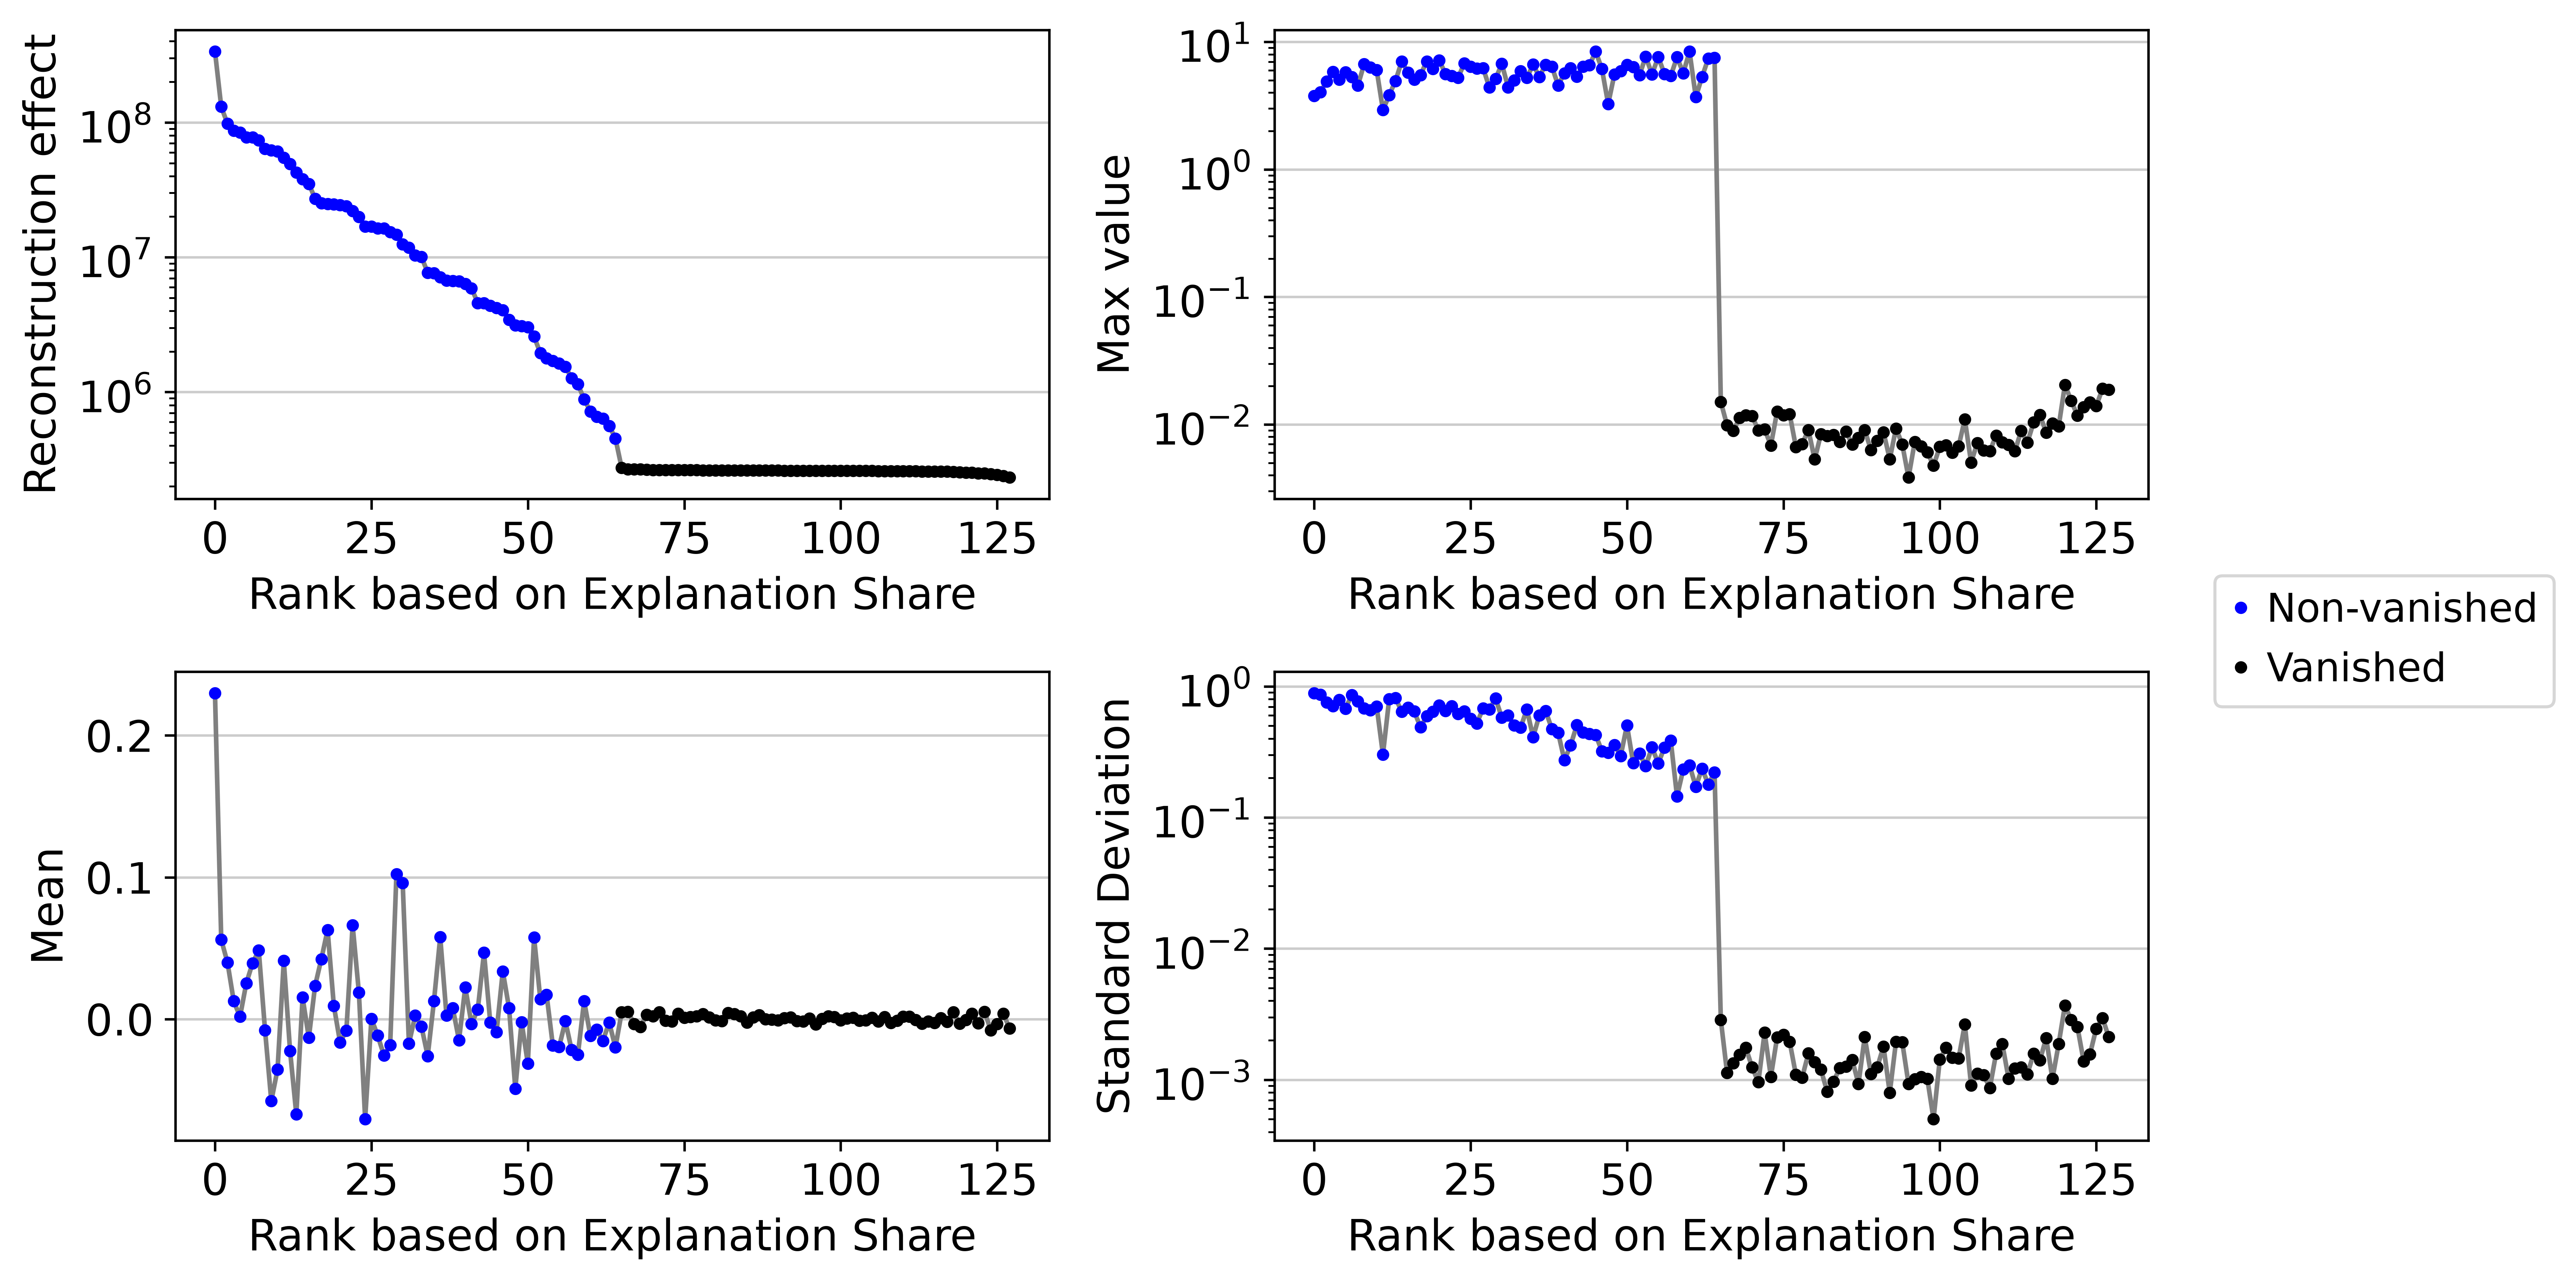

[fig] /home/albertoc/Desktop/QCB-Master-Thesis/02_integration_benchmark/figures/drvi_unscaled_128/latent_dimension_stats_drvi_unscaled_128.png


PosixPath('/home/albertoc/Desktop/QCB-Master-Thesis/02_integration_benchmark/figures/drvi_unscaled_128/latent_dimension_stats_drvi_unscaled_128.png')

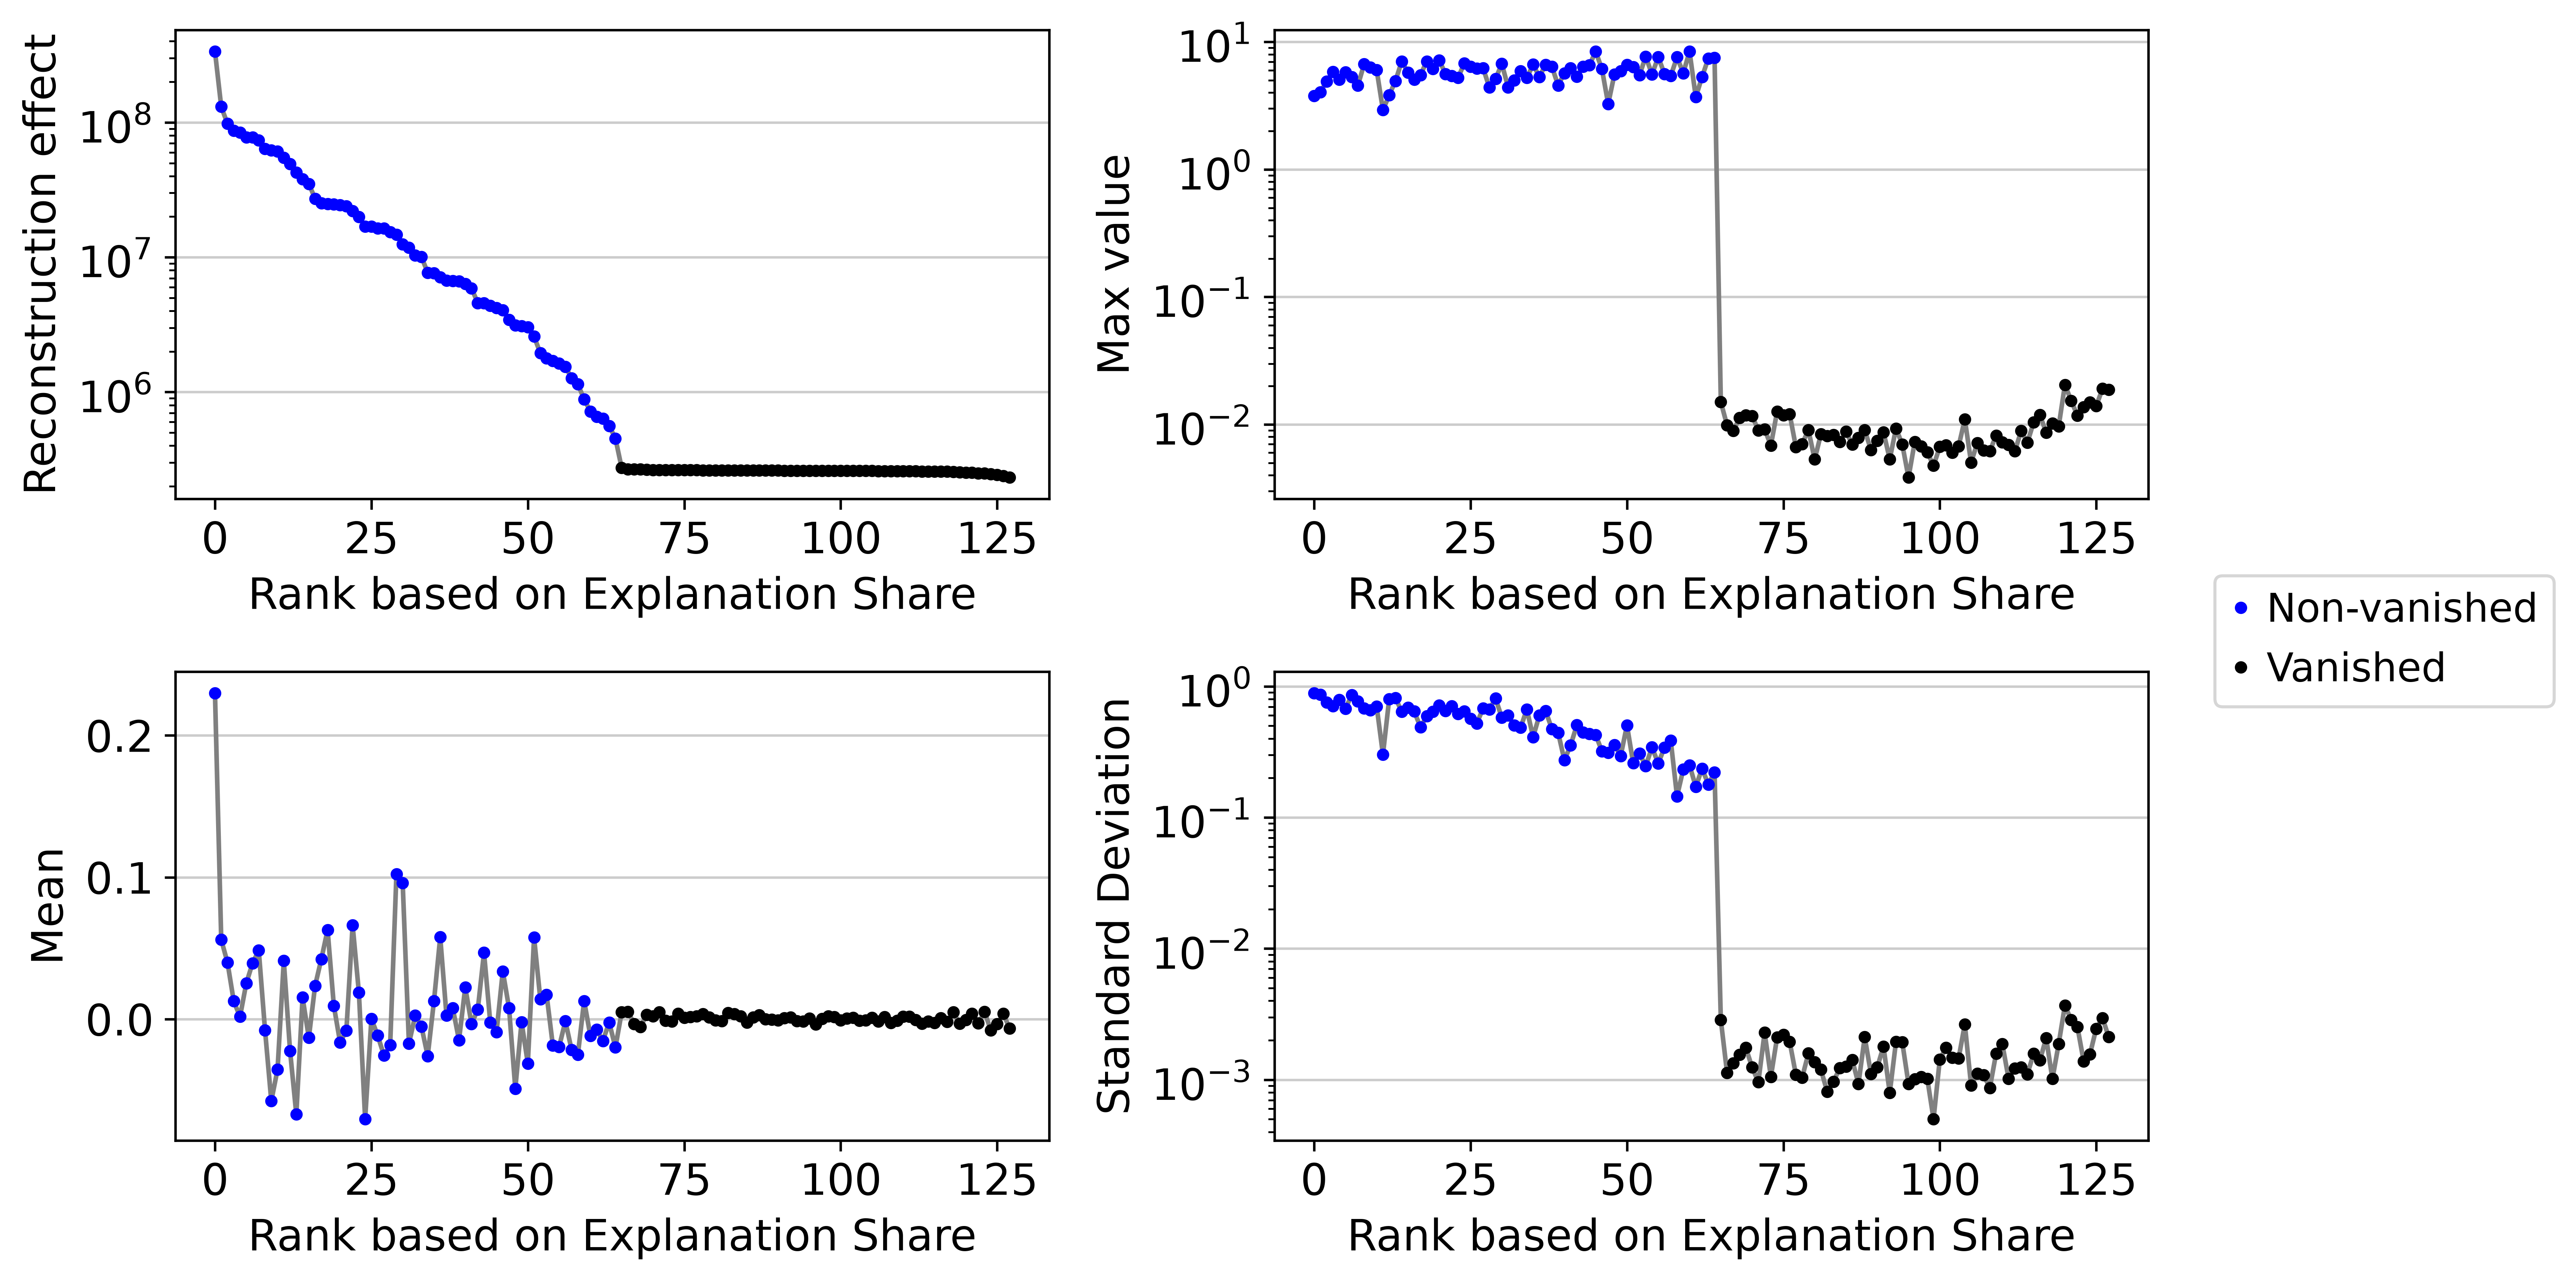

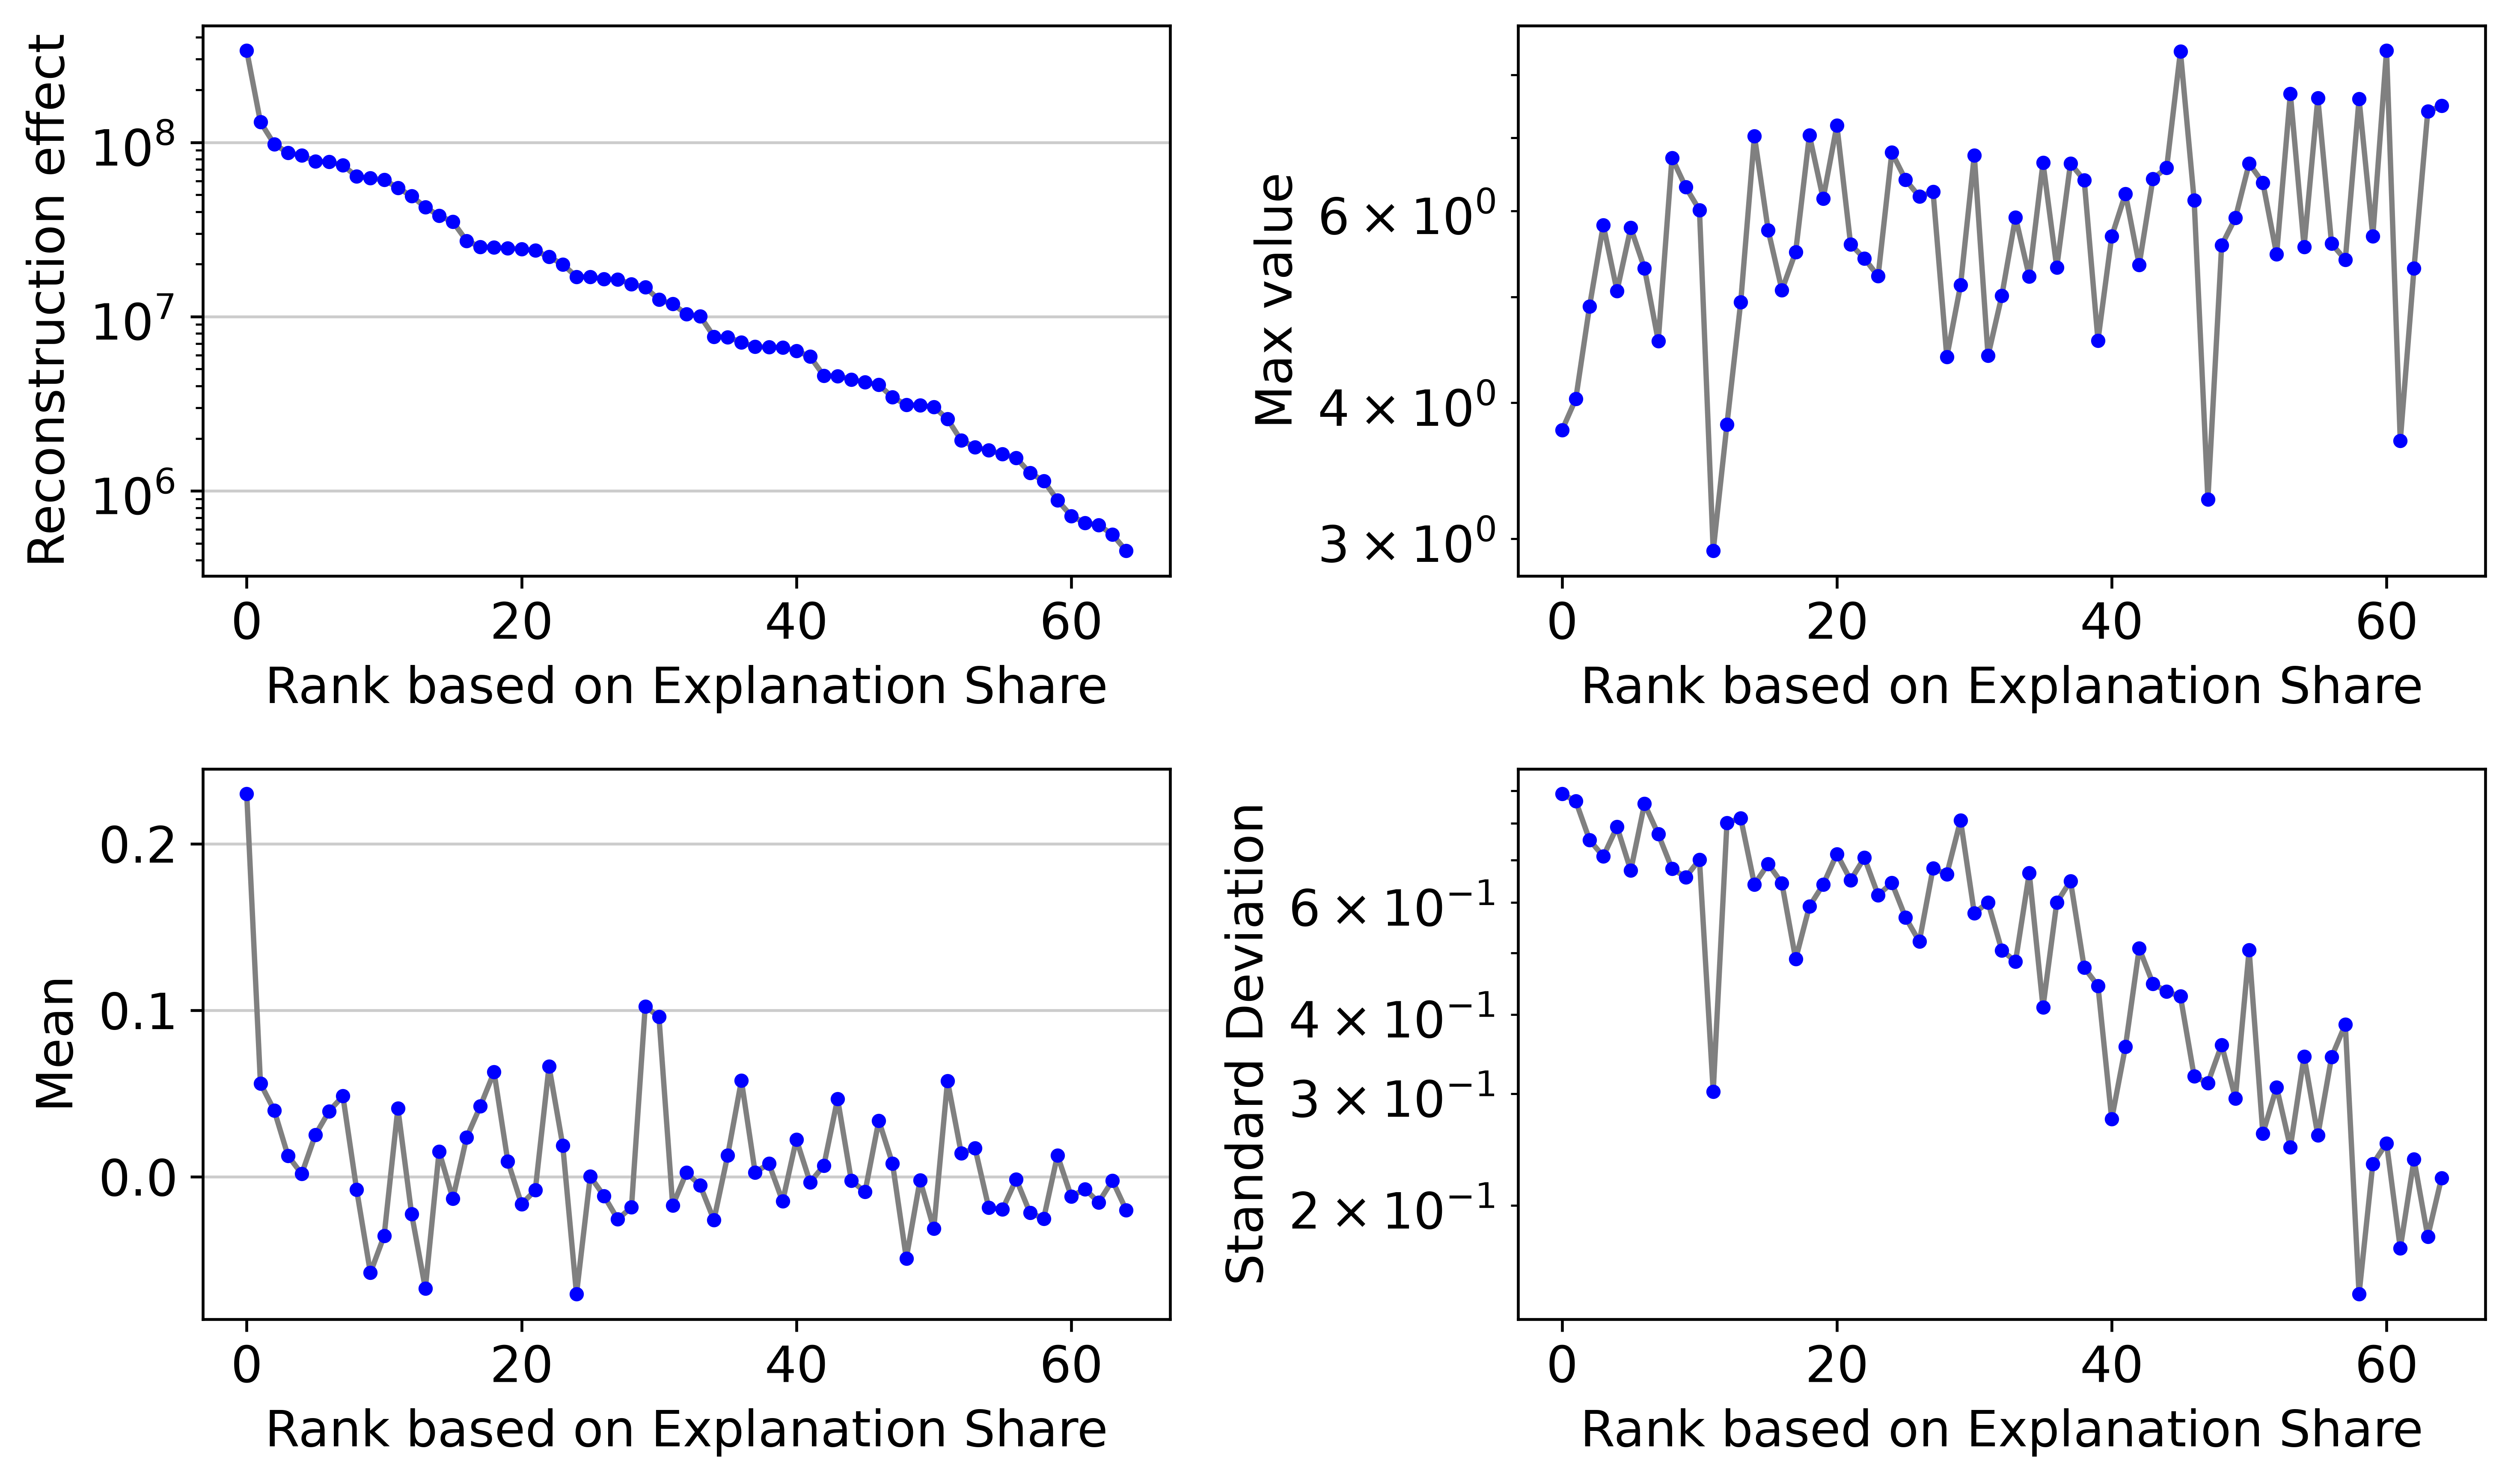

[fig] /home/albertoc/Desktop/QCB-Master-Thesis/02_integration_benchmark/figures/drvi_unscaled_128/latent_dimension_stats_rmVanished_drvi_unscaled_128.png


PosixPath('/home/albertoc/Desktop/QCB-Master-Thesis/02_integration_benchmark/figures/drvi_unscaled_128/latent_dimension_stats_rmVanished_drvi_unscaled_128.png')

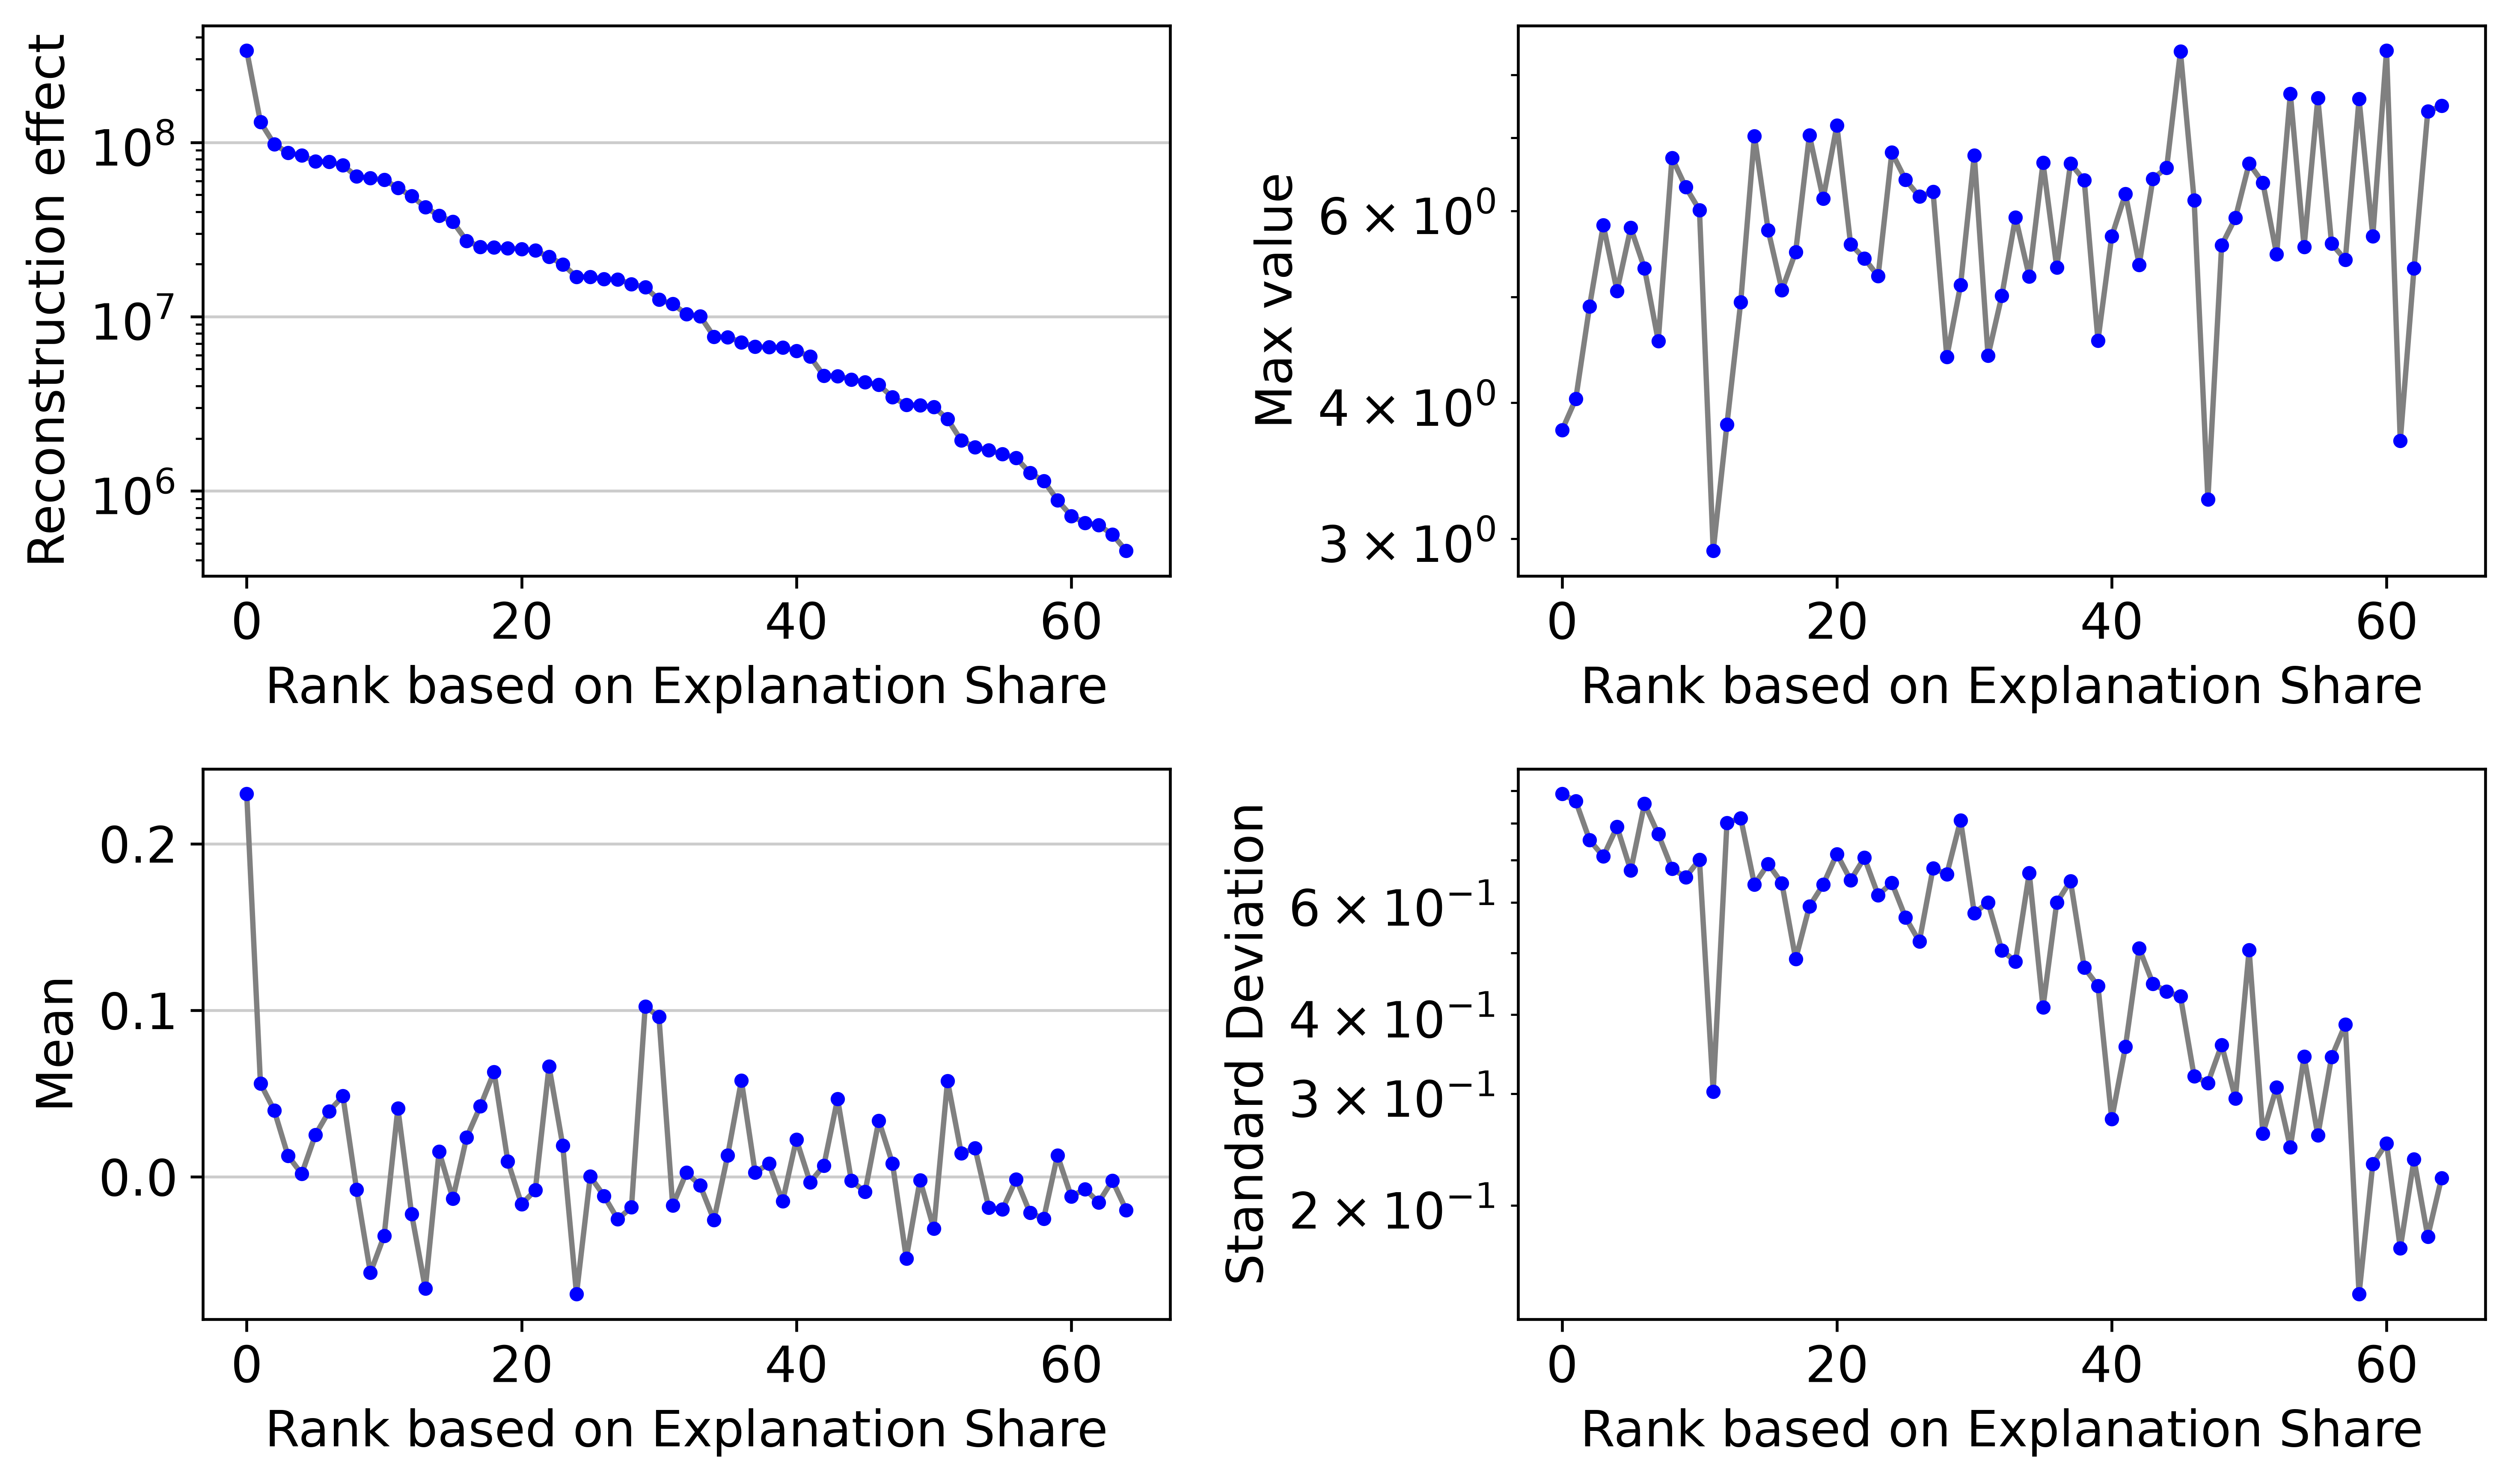

In [ ]:
# Per-dimension statistics: reconstruction effect, max value, mean, std.
drvi.utils.pl.plot_latent_dimension_stats(embed, ncols=2, show=False)
savefig("latent_dimension_stats")

# The same, vanished dimensions dropped: the informative half of the plot above.
drvi.utils.pl.plot_latent_dimension_stats(embed, ncols=2, remove_vanished=True, show=False)
savefig("latent_dimension_stats_rmVanished")

In [ ]:
# Every non-vanished dimension on the UMAP (remove_vanished defaults to True here).
drvi.utils.pl.plot_latent_dims_in_umap(embed, show=False)
savefig("latent_dims_in_umap")
plt.show()

{'heatmap_ax': <Axes: >, 'groupby_ax': <Axes: ylabel='cell_type'>}

[fig] /home/albertoc/Desktop/QCB-Master-Thesis/02_integration_benchmark/figures/drvi_unscaled_128/latent_dims_in_heatmap_cell_type_drvi_unscaled_128.png


PosixPath('/home/albertoc/Desktop/QCB-Master-Thesis/02_integration_benchmark/figures/drvi_unscaled_128/latent_dims_in_heatmap_cell_type_drvi_unscaled_128.png')

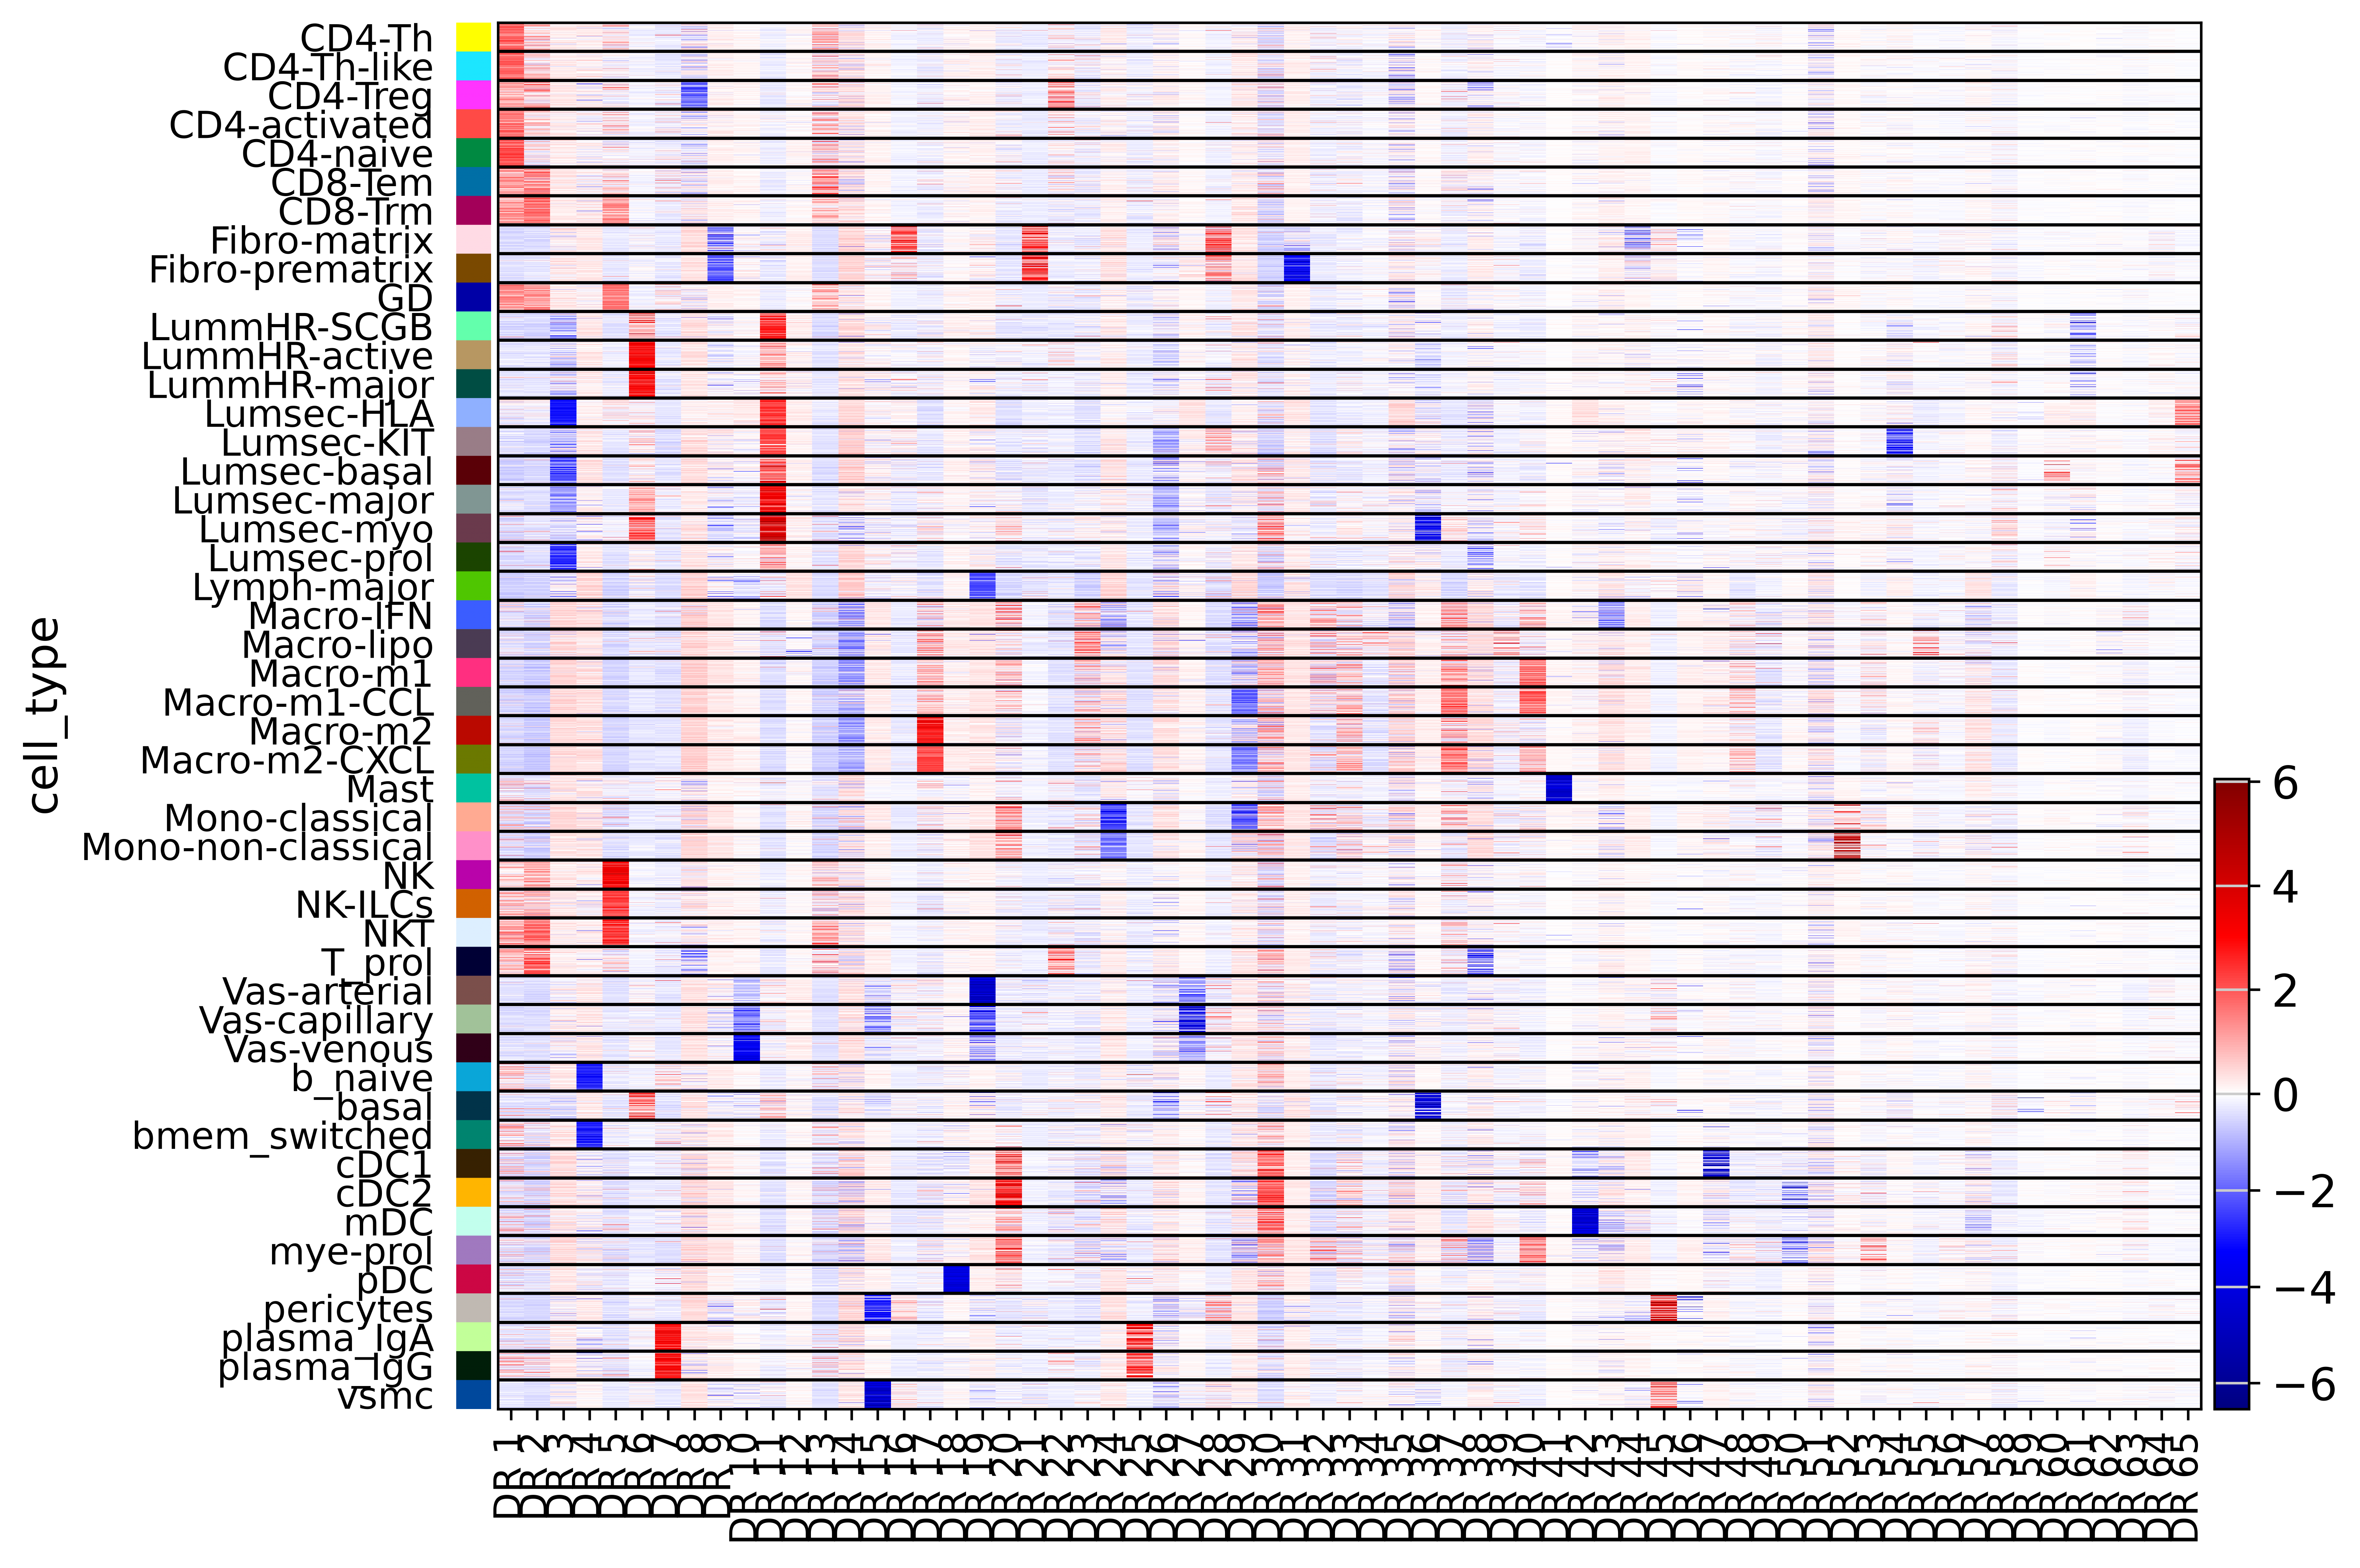

{'heatmap_ax': <Axes: >, 'groupby_ax': <Axes: ylabel='cell_type'>}

[fig] /home/albertoc/Desktop/QCB-Master-Thesis/02_integration_benchmark/figures/drvi_unscaled_128/latent_dims_in_heatmap_cell_type_sorted_drvi_unscaled_128.png


PosixPath('/home/albertoc/Desktop/QCB-Master-Thesis/02_integration_benchmark/figures/drvi_unscaled_128/latent_dims_in_heatmap_cell_type_sorted_drvi_unscaled_128.png')

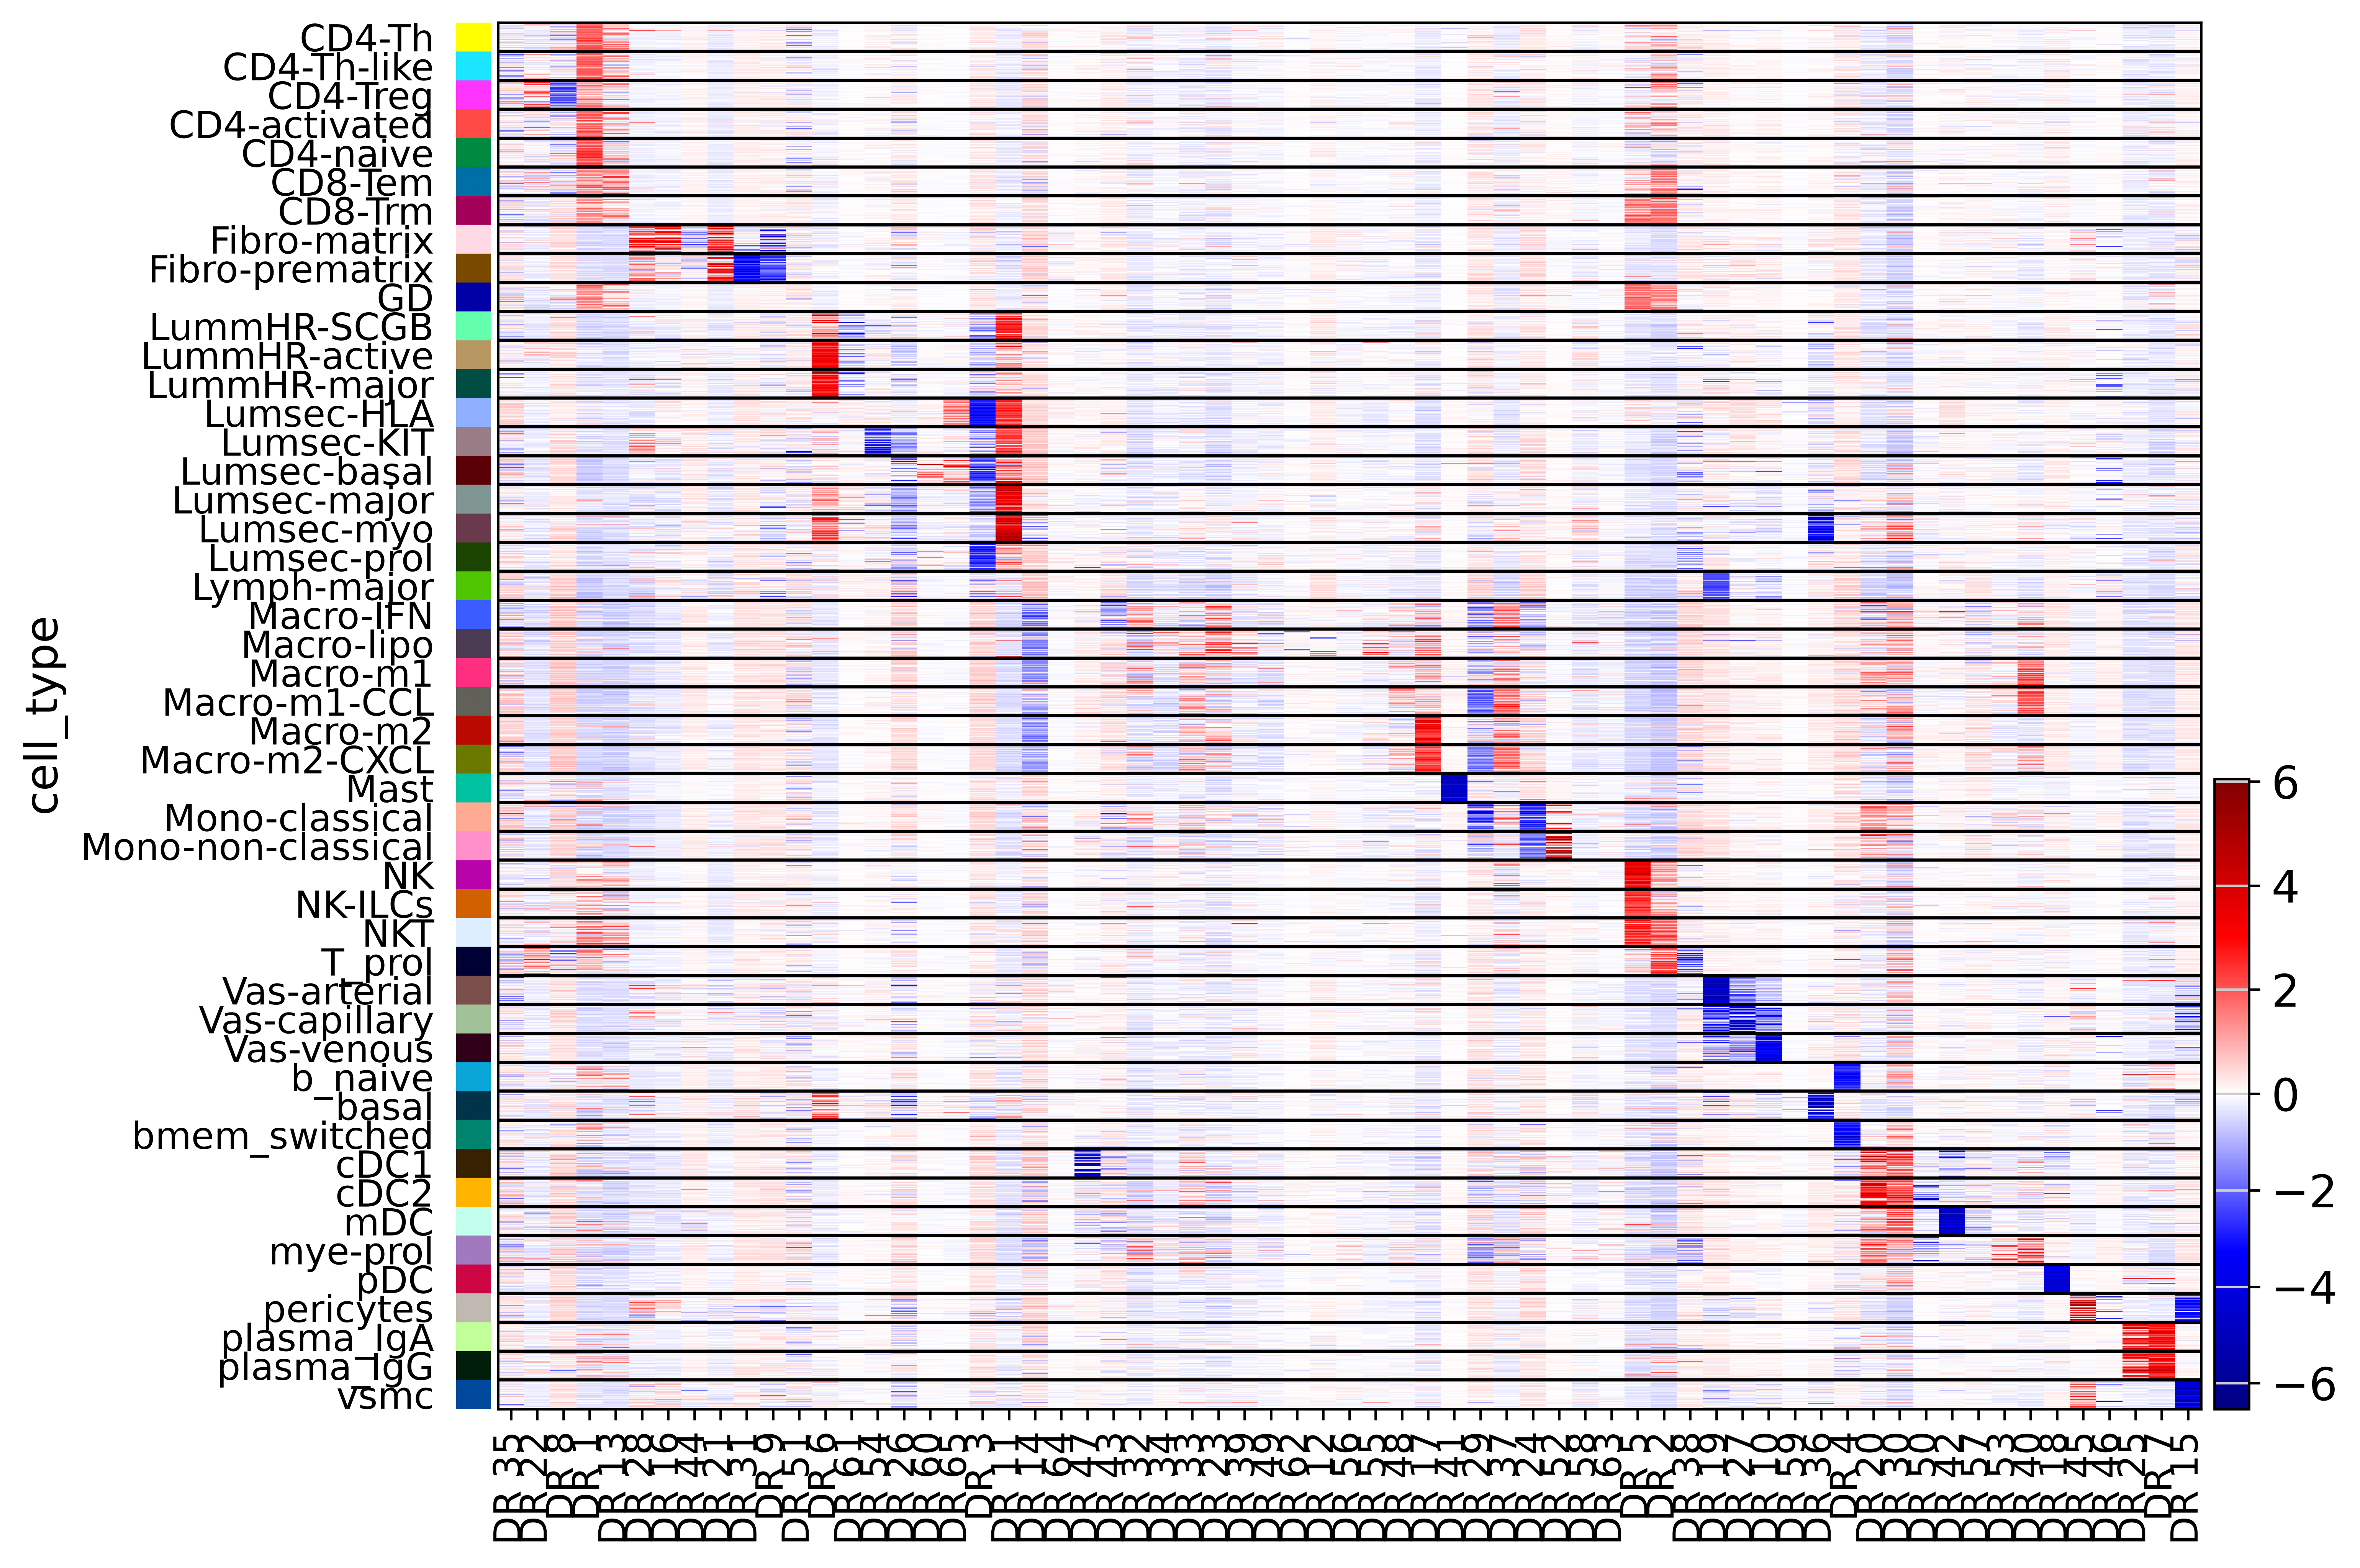

In [ ]:
# Dimension vs cell type, sorted by dimension and then by label.
drvi.utils.pl.plot_latent_dims_in_heatmap(embed, "cell_type", title_col="title", show=False)
savefig("latent_dims_in_heatmap_cell_type")

drvi.utils.pl.plot_latent_dims_in_heatmap(embed, "cell_type", title_col="title",
                                          sort_by_categorical=True, show=False)
savefig("latent_dims_in_heatmap_cell_type_sorted")
plt.show()

In [ ]:
# The same heatmap against the batch
drvi.utils.pl.plot_latent_dims_in_heatmap(embed, "cohort", title_col="title", show=False)
savefig("latent_dims_in_heatmap_cohort")
plt.show()

# And against treatment
drvi.utils.pl.plot_latent_dims_in_heatmap(embed, "treatment", title_col="title", show=False)
savefig("latent_dims_in_heatmap_treatment")
plt.show()

# And against phase
drvi.utils.pl.plot_latent_dims_in_heatmap(embed, "phase", title_col="title", show=False)
savefig("latent_dims_in_heatmap_phase")
plt.show()

### Interpretability (OOD scores)

The out-of-distribution scores come from the decoder reconstructions, so they are fast and
they favour the genes that are specific to a dimension.

In [ ]:
model.plot_interpretability_scores(embed, adata, show=False)
savefig("ood_interpretability_scores")
plt.show()

In [22]:
# Genes (rows) appear in adata order and are not sorted.
ood_scores = model.get_interpretability_scores(embed, adata)
ood_scores.iloc[:10, :10]

title,DR 1+,DR 1-,DR 2+,DR 2-,DR 3+,DR 3-,DR 4+,DR 4-,DR 5+,DR 5-
ISG15,0.076498,0.000000e+00,6.925867e-02,8.559950e-13,5.177566e-10,0.026598,9.399895e-11,0.075904,3.470261e-02,6.995084e-12
TNFRSF18,0.021888,0.000000e+00,8.989433e-02,0.000000e+00,0.000000e+00,0.011833,0.000000e+00,0.000235,2.347391e-02,0.000000e+00
TNFRSF4,0.077811,0.000000e+00,9.044420e-04,0.000000e+00,0.000000e+00,0.000039,0.000000e+00,0.000009,2.066069e-03,0.000000e+00
TAS1R3,0.000139,4.279975e-13,1.295046e-05,3.744978e-13,0.000000e+00,0.042738,0.000000e+00,0.002478,2.261837e-05,1.671865e-13
MXRA8,0.000002,0.000000e+00,7.515069e-07,0.000000e+00,0.000000e+00,0.035531,0.000000e+00,0.000002,4.406118e-07,8.292451e-13
MMP23B,0.000030,0.000000e+00,1.782529e-04,0.000000e+00,0.000000e+00,0.000125,0.000000e+00,0.000004,1.600423e-02,0.000000e+00
SMIM1,0.001157,3.018720e-11,1.663041e-04,2.340611e-11,8.426201e-13,0.157513,2.739184e-11,0.000454,1.453873e-04,5.177432e-11
TNFRSF25,0.517483,0.000000e+00,4.854873e-02,0.000000e+00,0.000000e+00,0.024470,0.000000e+00,0.000115,9.436466e-03,0.000000e+00
TNFRSF9,0.000668,0.000000e+00,1.784592e+00,0.000000e+00,0.000000e+00,0.000002,0.000000e+00,0.000094,3.956473e-03,0.000000e+00
RBP7,0.000003,0.000000e+00,3.027070e-07,0.000000e+00,0.000000e+00,0.011106,0.000000e+00,0.000003,4.720002e-08,0.000000e+00


The two halves of OOD_combined: the min_possible and max_possible log-fold-changes of each
dimension in the OOD setting. See the paper appendix for how they combine.

In [23]:
ood_max = model.get_interpretability_scores(embed, adata, key="OOD_max_possible")
ood_min = model.get_interpretability_scores(embed, adata, key="OOD_min_possible")
ood_max.iloc[:10, :10]
ood_min.iloc[:10, :10]

title,DR 1+,DR 1-,DR 2+,DR 2-,DR 3+,DR 3-,DR 4+,DR 4-,DR 5+,DR 5-
ISG15,2.682964,1.192093e-06,2.602447,1.438926e-05,3.095234e-04,1.564420,1.345943e-04,2.674351,2.156563,3.531400e-05
TNFRSF18,1.678510,0.000000e+00,2.506697,0.000000e+00,6.731819e-07,1.062412,7.012311e-08,0.262127,1.671134,1.402462e-08
TNFRSF4,2.841947,0.000000e+00,0.609950,0.000000e+00,7.292804e-07,0.103164,2.804924e-08,0.073754,0.874090,0.000000e+00
TAS1R3,0.018786,9.817236e-07,0.005656,9.957482e-07,0.000000e+00,0.075908,1.402462e-08,0.077952,0.007559,6.030588e-07
MXRA8,0.023003,1.416487e-06,0.014621,2.678703e-06,1.542709e-07,1.295810,2.861023e-06,0.024478,0.011732,6.311080e-06
MMP23B,0.085957,1.093921e-06,0.196025,3.365909e-07,0.000000e+00,0.126628,2.412235e-06,0.030713,1.383483,0.000000e+00
SMIM1,0.170522,2.778278e-05,0.064420,2.350527e-05,2.103693e-06,1.173700,2.447297e-05,0.108725,0.062250,3.479509e-05
TNFRSF25,2.396450,0.000000e+00,1.137203,0.000000e+00,6.731819e-07,0.681457,2.804925e-07,0.075432,0.591588,9.817236e-08
TNFRSF9,0.277952,0.000000e+00,3.889789,0.000000e+00,3.085417e-07,0.011042,3.786648e-07,0.108290,0.612296,4.207387e-08
RBP7,0.032873,0.000000e+00,0.010755,1.402462e-07,1.809176e-06,0.957900,5.890341e-07,0.034688,0.004384,3.786648e-07


title,DR 1+,DR 1-,DR 2+,DR 2-,DR 3+,DR 3-,DR 4+,DR 4-,DR 5+,DR 5-
ISG15,0.028361,0.000000e+00,0.026096,2.804924e-08,6.451326e-07,0.011053,2.524432e-07,0.028214,0.015812,5.609849e-08
TNFRSF18,0.012935,0.000000e+00,0.034735,0.000000e+00,0.000000e+00,0.007237,0.000000e+00,0.000880,0.013277,0.000000e+00
TNFRSF4,0.027376,0.000000e+00,0.001412,0.000000e+00,0.000000e+00,0.000172,0.000000e+00,0.000125,0.002328,0.000000e+00
TAS1R3,0.007270,4.347633e-07,0.002151,3.365909e-07,0.000000e+00,0.036239,2.804924e-08,0.031383,0.002884,2.664678e-07
MXRA8,0.000071,0.000000e+00,0.000045,0.000000e+00,0.000000e+00,0.014333,0.000000e+00,0.000076,0.000036,5.609849e-08
MMP23B,0.000331,0.000000e+00,0.000807,0.000000e+00,0.000000e+00,0.000518,0.000000e+00,0.000114,0.011270,0.000000e+00
SMIM1,0.006772,1.037822e-06,0.002451,9.256251e-07,1.402462e-07,0.099281,9.817236e-07,0.004148,0.002301,1.290265e-06
TNFRSF25,0.215627,0.000000e+00,0.041954,0.000000e+00,0.000000e+00,0.022484,0.000000e+00,0.001511,0.015679,0.000000e+00
TNFRSF9,0.002375,0.000000e+00,0.452494,0.000000e+00,0.000000e+00,0.000087,0.000000e+00,0.000848,0.006329,0.000000e+00
RBP7,0.000076,0.000000e+00,0.000024,0.000000e+00,0.000000e+00,0.005703,0.000000e+00,0.000080,0.000010,0.000000e+00


In [ ]:
model.plot_interpretability_scores(embed, adata, key="OOD_max_possible", show=False)
savefig("ood_max_interpretability_scores")
plt.show()

model.plot_interpretability_scores(embed, adata, key="OOD_min_possible", show=False)
savefig("ood_min_interpretability_scores")
plt.show()

### Interpretability (IND scores)

This approach iterates over all the cells and averages the effect of each latent factor on
each gene; the scores are already stored in embed.

They reflect the broad mechanistic effect of a dimension. Genes are not filtered for
uniqueness, so a gene shared by several dimensions keeps a high score in all of them: the
complete picture of what a factor moves, as opposed to the OOD scores' specific one.

In [ ]:
model.plot_interpretability_scores(embed, adata, key="IND_linear_weighted_mean", show=False)
savefig("ind_linear_weighted_mean")
plt.show()

In [26]:
# Genes (rows) appear in adata order and are not sorted.
ind_scores = model.get_interpretability_scores(embed, adata, key="IND_linear_weighted_mean")
ind_scores.iloc[:10, :10]

title,DR 1+,DR 1-,DR 2+,DR 2-,DR 3+,DR 3-,DR 4+,DR 4-,DR 5+,DR 5-
ISG15,1.466216,2.025538e-07,1.202631,4.943194e-07,8.430822e-06,2.016082,5.995714e-06,1.395502,1.315605,3.232832e-07
TNFRSF18,2.130843,4.985571e-10,1.370655,1.121110e-10,1.770040e-07,2.774250,6.359024e-07,1.287127,3.227525,3.734095e-09
TNFRSF4,2.921013,5.859742e-10,0.396924,4.215907e-08,7.916012e-06,0.553190,7.706497e-07,0.872484,2.170071,3.116880e-08
TAS1R3,0.904001,2.211045e-04,0.489095,6.843832e-04,9.123839e-08,0.600365,8.443528e-05,1.568025,0.530265,9.662064e-05
MXRA8,0.784364,2.231430e-04,0.453666,1.264710e-03,7.918121e-08,2.109682,1.697936e-03,0.876655,0.634595,9.803603e-04
MMP23B,0.998356,1.290057e-04,1.082880,1.146932e-04,6.602412e-08,1.364156,8.472929e-04,0.657424,2.692150,6.749501e-06
SMIM1,1.566602,1.676410e-03,0.907440,2.721565e-03,5.814894e-06,2.630782,4.743392e-03,1.617827,1.416900,1.349696e-03
TNFRSF25,3.814398,9.825358e-08,1.334200,2.208630e-06,2.317495e-06,1.801537,9.846051e-05,1.056841,1.062934,8.031781e-06
TNFRSF9,0.697322,2.746615e-06,2.910676,1.195388e-07,6.878954e-05,0.122145,5.577826e-05,0.502580,1.678320,3.158196e-06
RBP7,0.655624,5.321973e-07,0.258242,1.389739e-06,6.992743e-07,2.636104,4.006618e-06,0.513285,0.211217,7.486018e-06


## A closer look at the dimensions owned by a single cell type

The heatmap above says which dimension responds to which label and
latent_dims_in_umap draws every surviving dimension at once, but neither answers the
question one dimension at a time: does a dimension that looks cell-type-specific in the
heatmap really light up that population, and only that population? This section puts the
two views side by side on the same UMAP and with the same point order - the cell type on
the left, the dimension on the right.

DRVI dimensions are directional: DR 18- is the negative half of dimension 18 and
DR 18+ the positive one, the two halves are independent programs and in general only one
of them belongs to the cell type. The right panel is therefore coloured by the projection
on the chosen half (-z for a - dimension, the convention of
plot_latent_dims_in_umap(directional=True)), so a higher value always means *further
along the named direction*. The colour scale is the dimension's own range widened to at
least [-1, 1], so a weak dimension is not stretched to look strong.

Which pairs get drawn is decided by the SMI screening below, following the DRVI
Identifying cell types of DRVI factors tutorial.

In [27]:
# Same embed_plot as the UMAP section; rebuilt if that section was skipped.
if "embed_plot" not in globals():
    _order = np.random.default_rng(globals().get("UMAP_SEED", 0)).permutation(embed.n_obs)
    embed_plot = ad.AnnData(
        obs=embed.obs.iloc[_order].copy(),
        obsm={"X_umap": embed.obsm["X_umap"][_order]},
        uns={k: v for k, v in adata.uns.items() if k.endswith("_colors")},
    )
    print(f"[rebuilt] embed_plot: {embed_plot.n_obs:,} cells")
else:
    print(f"embed_plot: {embed_plot.n_obs:,} cells")

embed_plot: 619,693 cells


In [28]:
def dim_values(dim_title, direction):
    """Projection on one half of a dimension (negated for "-") and its colour range,
    at least [-1, 1] as in DRVI."""
    hits = embed.var_names[embed.var["title"] == dim_title]
    if len(hits) != 1:
        raise KeyError(f"{dim_title!r} is not a dimension of this run")
    var_name = hits[0]

    sign = 1.0 if direction == "+" else -1.0
    values = pd.Series(np.asarray(embed[:, var_name].X).ravel(), index=embed.obs_names)

    lo, hi = float(embed.var.loc[var_name, "min"]), float(embed.var.loc[var_name, "max"])
    if sign < 0:
        lo, hi = -hi, -lo

    return sign * values, (min(lo, -1.0), max(hi, 1.0))


def plot_dim_vs_cell_type(cell_type, dim_title, direction, size=4, figsize=(11.5, 4.8)):
    """Cell type (left) and its dimension (right) on the same UMAP. Returns the figure."""
    label = f"{dim_title}{direction}"
    values, (vmin, vmax) = dim_values(dim_title, direction)
    values = values.loc[embed_plot.obs_names]

    # A light companion object: only the UMAP and the one column to colour by.
    panel = ad.AnnData(
        obs=pd.DataFrame({label: values.to_numpy()}, index=embed_plot.obs_names),
        obsm={"X_umap": embed_plot.obsm["X_umap"]},
    )

    # No tight_layout here: it collapses the colour bar sc.pl.umap attaches to ax.
    fig, axes = plt.subplots(1, 2, figsize=figsize)
    sc.pl.umap(embed_plot, color="cell_type", groups=[cell_type], title=cell_type,
               ax=axes[0], show=False, legend_loc="none", na_in_legend=False,
               size=size, frameon=False)
    sc.pl.umap(panel, color=label, title=label, ax=axes[1], show=False,
               size=size, frameon=False, cmap=drvi.utils.pl.cmap.saturated_sky_cmap,
               vmin=vmin, vcenter=0, vmax=vmax)

    # The number behind the picture: the same contrast the heatmap shows as one cell.
    is_ct = embed_plot.obs["cell_type"].to_numpy() == cell_type
    print(f"{label}: {values[is_ct].mean():+.2f} mean over the {int(is_ct.sum()):,} "
          f"{cell_type} cells vs {values[~is_ct].mean():+.2f} over the other "
          f"{int((~is_ct).sum()):,} cells")
    return fig

### Which factor encodes which cell type: SMI

Picking the pairs by how far a label sits along an axis answers the wrong question: a
lineage program shared by three related labels can put all three far out, and the panel
then shows a compartment rather than a cell type. The DRVI tutorial scores the thing we
actually want - a one-to-one correspondence between a factor direction and a label -
with the Scaled Mutual Information, normalised to [0, 1].

Three steps, taken from the tutorial:

- build_directional_df turns the latent space into a cells x factor-directions matrix.
  Each dimension is split in two, the vanished halves are dropped, and each half is
  clipped at zero (pos = z.clip(min=0), neg = -z.clip(max=0)): the positive half
  reads zero wherever the factor is negative and vice versa, so the two halves become two
  independent variables, each switched off outside its own semiaxis.
- smi_matches hands that matrix to DiscreteDisentanglementBenchmark with
  metrics=["SMI"]. Internally each direction is binned into 10 uniform bins and the
  mutual information between the binned factor and the one-hot indicator of each label is
  divided by that label's entropy - the normalisation that makes a rare label and an
  abundant one comparable.
- store_matches writes the best match per direction back into embed.var as
  positive_direction_match_with_suffix / negative_direction_match_with_suffix and
  the whole table into embed.uns, the layout the other notebooks of the tutorial series
  read.

The annotation never enters DRVI's training, so it cannot bias the factors: it only names
them afterwards. What SMI measures is the agreement between a factor and the annotation -
not between a factor and the truth - so a mediocre score can be the label's fault as much
as the factor's, and the assignments are worth checking against each dimension's top genes
(the interpretability scores above).

In [29]:
# Imports used only in this section.
import networkx as nx
from drvi.utils.metrics import DiscreteDisentanglementBenchmark


def build_directional_df(embed):
    """Cells x (non-vanished factor-directions). Column names carry a '+'/'-' suffix."""
    embed_pos = embed[:, ~embed.var["vanished_positive_direction"]].copy()
    embed_neg = embed[:, ~embed.var["vanished_negative_direction"]].copy()
    embed_pos.var.index = embed_pos.var["title"] + "+"
    embed_neg.var.index = embed_neg.var["title"] + "-"
    embed_pos.X = embed_pos.X.clip(min=0)
    embed_neg.X = -embed_neg.X.clip(max=0)
    return pd.concat([embed_pos.to_df(), embed_neg.to_df()], axis=1).loc[embed.obs.index]


def smi_matches(embed_directional_df, target, threshold):
    """SMI matrix (directions x categories) and the pairs >= threshold, sorted."""
    benchmark = DiscreteDisentanglementBenchmark(
        embed_directional_df.values,
        dim_titles=embed_directional_df.columns,
        discrete_target=target,
        metrics=["SMI"],
        aggregation_methods=[],
    )
    benchmark.evaluate()
    smi = benchmark.get_results_details()["SMI"]
    smi.index.name = "title"

    top = (
        smi.reset_index()
        .melt(id_vars="title", value_vars=smi.columns)
        .query("value >= @threshold")
        .reset_index(drop=True)
        .sort_values("value", ascending=False)
    )
    return smi, top


def store_matches(embed, top, suffix):
    """Best match per direction into embed.var, full table into embed.uns."""
    first = top.drop_duplicates(subset=["title"]).copy()
    first["direction"] = first["title"].str[-1:]
    first["title"] = first["title"].str[:-1]

    embed.var.set_index("title", drop=False, inplace=True)
    for d, sign in [("positive", "+"), ("negative", "-")]:
        col = f"{d}_direction_match_with_{suffix}"
        embed.var[col] = None
        sub = first.query("direction == @sign")
        embed.var.loc[sub["title"], col] = sub["variable"].values
    embed.var.index = embed.var["original_dim_id"].astype(int).astype(str)
    embed.var.index.name = None

    embed.uns[f"best_smi_matching_{suffix}_results"] = top


def plot_packed_network(df, title_col="title", var_col="variable", val_col="value",
                        figsize=(20, 20)):
    """Visualize factor-cell type associations as a network with edge weights."""
    G = nx.from_pandas_edgelist(df, title_col, var_col, edge_attr=val_col)

    pos = {}
    components = sorted(nx.connected_components(G), key=len, reverse=True)
    cols = 3
    for i, nodes in enumerate(components):
        sub_pos = nx.spring_layout(G.subgraph(nodes), weight=val_col, k=0.5)
        r, c = divmod(i, cols)
        for n, (x, y) in sub_pos.items():
            pos[n] = (x + c * 3, y - r * 3)

    plt.figure(figsize=figsize)
    titles = set(df[title_col])
    weights = [d[val_col] for u, v, d in G.edges(data=True)]
    nx.draw(
        G, pos,
        with_labels=True, font_size=8, font_weight="bold", node_size=600,
        node_color=["#A0CBE2" if n in titles else "#FF9E9E" for n in G.nodes()],
        width=[w * 4 for w in weights],
        edge_color=weights, edge_cmap=plt.cm.Oranges, alpha=0.6,
    )
    edge_labels = {(u, v): f"{d[val_col]:.2f}" for u, v, d in G.edges(data=True)}
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=7)
    plt.axis("off")

In [30]:
ANNOT_COL = "cell_type" # the CellTypist labels, as everywhere else in the benchmark
SMI_THRESHOLD = 0.7 # the tutorial's default: below it the match is not one-to-one

# Slowest cell of the section (minutes).
embed_directional_df = build_directional_df(embed)
smi_similarity, smi_top_matches = smi_matches(
    embed_directional_df, embed.obs[ANNOT_COL], SMI_THRESHOLD
)

print(f"SMI matrix shape: {smi_similarity.shape} (factor-directions x cell types)")
print(f"Factor-cell type pairs with SMI >= {SMI_THRESHOLD}: {len(smi_top_matches)}")
smi_top_matches

SMI matrix shape: (128, 48) (factor-directions x cell types)
Factor-cell type pairs with SMI >= 0.7: 10


,title,variable,value
3,DR 41-,Mast,0.978514
7,DR 18-,pDC,0.963184
6,DR 42-,mDC,0.913285
5,DR 10-,Vas-venous,0.880763
9,DR 15-,vsmc,0.861021
4,DR 19-,Vas-arterial,0.840518
1,DR 6+,LummHR-major,0.820663
0,DR 31-,Fibro-prematrix,0.762724
2,DR 17+,Macro-m2,0.708201
8,DR 7+,plasma_IgG,0.700505


In [ ]:
# Matches as a graph: components larger than one edge are the interesting ones.
plot_packed_network(smi_top_matches, figsize=(20, 20))
savefig("smi_cell_type_network")
plt.show()

In [32]:
# As in the tutorial, so a later notebook can reuse the assignments.
store_matches(embed, smi_top_matches, suffix="celltypist")
(
    embed.var["positive_direction_match_with_celltypist"].dropna().unique(),
    embed.var["negative_direction_match_with_celltypist"].dropna().unique(),
)

(array(['LummHR-major', 'plasma_IgG', 'Macro-m2'], dtype=object),
 array(['vsmc', 'pDC', 'Mast', 'Vas-venous', 'Fibro-prematrix', 'mDC',
        'Vas-arterial'], dtype=object))

In [33]:
# Table to TABLE_DIR; rewriting the ~730 MB LATENT_H5AD is opt-in.
SMI_CSV = TABLE_DIR / f"smi_cell_type_matches_{RUN_ID}.csv"
smi_top_matches.to_csv(SMI_CSV, index=False)
print(f"[write] {SMI_CSV}")

WRITE_BACK_EMBED = False
if WRITE_BACK_EMBED:
    ad.settings.allow_write_nullable_strings = True
    embed.write_h5ad(LATENT_H5AD)
    print(f"[write] {LATENT_H5AD}")

[write] /home/albertoc/Desktop/QCB-Master-Thesis/02_integration_benchmark/tables/drvi_unscaled_128/smi_cell_type_matches_drvi_unscaled_128.csv


### The pairs, one at a time

Every match above, as the two-panel figure: the label on the left, the factor direction
SMI paired it with on the right. A high SMI says the two carry the same information; the
figure says whether they carry it in the same place, which is the part a number cannot
show.

In [ ]:
# title carries the direction as its last character: "DR 18-" -> ("DR 18", "-").
for row in smi_top_matches.itertuples(index=False):
    dim_title, direction, cell_type = row.title[:-1], row.title[-1], row.variable
    print(f"SMI {row.value:.3f}", end="  ")
    fig = plot_dim_vs_cell_type(cell_type, dim_title, direction)
    savefig(f"dim_vs_cell_type_{cell_type}_{dim_title.replace(' ', '')}{direction}", fig=fig)
    plt.show()

## What the factors are doing: biological processes

SMI above answers "which factor is which cell type", and it can only answer it for the labels
this dataset carries. Every direction it leaves unnamed is still a candidate for something: a
factor without a cell type match is not necessarily empty, it can be a process running across
several types (cell cycle, interferon response, hypoxia, dissociation stress), which is exactly
the thing SMI is built not to reward.

What this section is for here. This notebook has a real CellTypist annotation over every
compartment of the dataset, so enrichment is a complement to SMI rather than a replacement
for it. SMI names the factors that behave like a cell type, enrichment names the ones that behave
like a program, and on a 128-dimensional latent space the second group is the larger one. It
also gives the benchmark a reading it otherwise lacks: a factor that encodes a process rather
than an identity is invisible to every label-based metric in 02_4.

This is the DRVI tutorial Identifying biological processes of DRVI factors, run on this
notebook's factors. Three non-LLM tools, all reading the same per-gene interpretability scores
computed above:

| Tool | Method | Input | What it adds |
| --- | --- | --- | --- |
| Enrichr (via GSEApy) | over-representation (ORA) | top-N gene list | fast, the largest library collection |
| g:Profiler | over-representation (ORA) | ordered gene query | g:SCS correction, ordered query |
| decoupler | regulon activity (ULM + MLM) | the whole score vector | transcription factors, not terms |

Cost. 128 latent dimensions would make 256 directions, but 63 of them vanished during
training, so the score table has 128 non-vanished directions, not 256. Both ORA tools issue one web request per direction that carries a gene
list, so this section takes tens of minutes and needs network. decoupler runs locally and is
fast.


### Setup

Three packages on top of the environment of this notebook: gseapy (1.3.0),
gprofiler-official (1.0.0) and decoupler (2.2.0), all three already in benchmark-py-r. On
any other environment they can be installed with pip: gseapy, gprofiler-official and
decoupler 2.0 or later.

Both ORA tools query a web service (Enrichr for the library, g:Profiler for the whole run), so
these cells need network and are the slow ones of the notebook. The imports are local to the
section, as in the SMI one, so the Libraries cell at the top does not have to be re-run.


In [35]:
# Local imports: only this section uses them.
import gseapy
from gprofiler import GProfiler
import decoupler as dc
from statsmodels.stats.multitest import multipletests


In [36]:
SCORE_KEY = "OOD_combined" # or "IND_linear_weighted_mean", with the higher cutoffs below

# Gene x direction score table read by every tool below (same as ood_scores above).
if SCORE_KEY == "OOD_combined" and "ood_scores" in globals():
    scores_df = ood_scores
    print("[reuse] ood_scores from the interpretability section above")
else:
    scores_df = model.get_interpretability_scores(embed, adata, key=SCORE_KEY)

# Background: the 2,000 HVGs of INPUT_H5AD.
gene_background = adata.var_names.tolist()

# One SMI target here; a dict, so targets can be added.
SMI_BY_TARGET = {"celltypist": smi_top_matches}

print(f"{scores_df.shape[0]:,} genes x {scores_df.shape[1]} factor directions, key={SCORE_KEY!r}")
print(f"background  {len(gene_background):,} genes (the HVG panel the benchmark integrates)")
print(f"SMI targets {list(SMI_BY_TARGET)}")


[reuse] ood_scores from the interpretability section above
2,000 genes x 128 factor directions, key='OOD_combined'
background  2,000 genes (the HVG panel the benchmark integrates)
SMI targets ['celltypist']


In [37]:
def top_genes(scores_df, col, cutoff, top_n):
    """Genes of a factor direction with score >= cutoff, at most `top_n`, best first."""
    s = scores_df[col]
    return s[s >= cutoff].nlargest(top_n).index.astype(str).tolist()


def factor_first(df):
    """`df` with the `factor` column moved to the front (no-op if empty or absent)."""
    if df.empty or "factor" not in df.columns:
        return df
    return df[["factor", *df.columns.drop("factor")]]


# Directions with no gene above the cutoff have no program and are skipped.
GENE_CUTOFF = 0.1 if SCORE_KEY == "OOD_combined" else 0.5 # ~0.1 for OOD, ~0.5 for IND
TOP_N = 100 # max genes per direction

sizes = pd.Series(
    {c: len(top_genes(scores_df, c, GENE_CUTOFF, TOP_N)) for c in scores_df.columns},
    name="n_genes",
)
print(f"directions with at least one gene past {GENE_CUTOFF}: "
      f"{(sizes > 0).sum()} / {len(sizes)}")
print(f"median list length among those: {int(sizes[sizes > 0].median()) if (sizes > 0).any() else 0} genes")
print(f"web requests this section will make: ~{2 * int((sizes > 0).sum())} "
      "(Enrichr + g:Profiler, one each per direction with a list)")
sizes.sort_values(ascending=False).head(10)


directions with at least one gene past 0.1: 62 / 128
median list length among those: 80 genes
web requests this section will make: ~124 (Enrichr + g:Profiler, one each per direction with a list)


DR 1+     100
DR 2+     100
DR 4-     100
DR 3-     100
DR 7+     100
DR 8-     100
DR 6+     100
DR 5+     100
DR 13+    100
DR 11+    100
Name: n_genes, dtype: int64

### 1. Enrichr (via GSEApy)

The plain over-representation test: take the top genes of a direction, ask whether any term of a
library is over-represented among them against the background, Benjamini-Hochberg over the terms
of that direction.

GO_Biological_Process_2023 is the tutorial's library. The appendix of the tutorial lists the
swap-ins - MSigDB_Hallmark_2020 for broad states, Reactome_Pathways_2024, KEGG_2026,
CellMarker_2024 and PanglaoDB_Augmented_2021 for markers - and only GSEAPY_DB has to change
to use one. On this dataset the marker libraries are worth a second pass: with every compartment
present, a direction can be a cell type program rather than a process, and CellMarker_2024
names that where GO only gestures at it.


In [38]:
GSEAPY_DB = "GO_Biological_Process_2023" # any Enrichr library, see the tutorial appendix
PADJ_THRESHOLD = 0.05


def run_gseapy_enrichr(scores_df, gene_sets, cutoff, top_n, padj_cutoff, background):
    rows = []
    for col in scores_df.columns:
        genes = top_genes(scores_df, col, cutoff, top_n)
        if not genes:
            continue
        try:
            enr = gseapy.enrich(gene_list=genes, gene_sets=gene_sets, background=background,
                                no_plot=True, outdir=None)
        except Exception as e:
            print(f"ORA failed for {col}: {e}")
            continue
        hits = enr.results[enr.results["Adjusted P-value"] < padj_cutoff]
        rows.append(hits.assign(factor=col))
    return factor_first(pd.concat(rows, ignore_index=True)) if rows else pd.DataFrame()


enrichr_results = run_gseapy_enrichr(
    scores_df, GSEAPY_DB, GENE_CUTOFF, TOP_N, PADJ_THRESHOLD, gene_background
)
n_sig = enrichr_results["factor"].nunique() if not enrichr_results.empty else 0
print(f"Enrichr: {n_sig} / {scores_df.shape[1]} factor directions with at least one term "
      f"at padj < {PADJ_THRESHOLD}")
enrichr_results.head()


Enrichr: 55 / 128 factor directions with at least one term at padj < 0.05


,factor,Gene_set,Term,P-value,Adjusted P-value,Old P-value,Old adjusted P-value,Odds Ratio,Combined Score,Genes
0,DR 1+,GO_Biological_Process_2023,T Cell Receptor Signaling Pathway (GO:0050852),1.605711e-06,0.000900,0,0,9.484848,126.546319,ITK;PTPRC;LCK;TRBC2;TXK;TRBC1;CD28;CD3G;CD3E;CD3D
1,DR 1+,GO_Biological_Process_2023,T Cell Activation (GO:0042110),2.488576e-06,0.000900,0,0,6.866093,88.598695,ITK;PTPRC;LCK;TRBC2;TRBC1;CD7;CD28;RHOH;CCR7;C...
2,DR 1+,GO_Biological_Process_2023,Alpha-Beta T Cell Activation (GO:0046631),1.407260e-05,0.003391,0,0,33.280702,371.788077,TRBC2;TRBC1;CD3G;CD3E;CD3D
3,DR 2+,GO_Biological_Process_2023,Regulation Of Lymphocyte Activation (GO:0051249),1.243971e-08,0.000009,0,0,41.217391,750.254292,KLRC2;KLRC3;LCK;SIT1;CRTAM;KLRD1;KLRC1;IKZF3
4,DR 2+,GO_Biological_Process_2023,T Cell Receptor Signaling Pathway (GO:0050852),1.517067e-07,0.000055,0,0,11.058855,173.638585,PTPRC;CD8B;CD8A;LCK;TRBC2;THEMIS;CTLA4;CD3G;PT...


In [39]:
# One row per factor direction: its single most significant term.
enrichr_top = (
    enrichr_results.sort_values("Adjusted P-value")
    .drop_duplicates(subset=["factor"], keep="first")
    [["factor", "Term", "Adjusted P-value", "Odds Ratio", "Genes"]]
    if not enrichr_results.empty else pd.DataFrame()
)
enrichr_top


,factor,Term,Adjusted P-value,Odds Ratio,Genes
823,DR 30+,Immunoglobulin Mediated Immune Response (GO:00...,2.737429e-16,225.614583,CD74;HLA-DRB5;HLA-DMA;HLA-DRA;FCER1A;HLA-DQA2;...
1046,DR 35-,Defense Response To Symbiont (GO:0140546),2.798345e-15,88.727273,GBP5;IFITM1;RSAD2;MX1;IFI6;ISG15;IFIT1;IFIT3;I...
1923,DR 58+,Cellular Response To Zinc Ion (GO:0071294),6.026437e-15,inf,MT2A;MT1M;MT1F;MT1G;MT1H;MT1X
558,DR 28+,Extracellular Matrix Organization (GO:0030198),9.740815e-15,17.331269,POSTN;COL14A1;LUM;COL11A1;MMP2;COL12A1;COL1A1;...
1537,DR 47-,Peptide Antigen Assembly With MHC Class II Pro...,3.113846e-12,438.750000,HLA-DRB5;HLA-DMA;HLA-DMB;HLA-DRA;HLA-DOB;HLA-D...
2032,DR 65+,Intermediate Filament Organization (GO:0045109),6.554322e-12,71.688953,DSP;KRT81;KRT23;KRT7;KRT5;KRT86;KRT19;KRT17;KR...
1583,DR 50-,MHC Class II Protein Complex Assembly (GO:0002...,8.630282e-11,244.750000,HLA-DRB5;HLA-DMB;HLA-DRA;HLA-DQA2;HLA-DQA1;HLA...
23,DR 4-,Immunoglobulin Mediated Immune Response (GO:00...,9.908397e-11,47.168582,CD74;HLA-DRB5;HLA-DMA;HLA-DMB;CD19;HLA-DRA;FCG...
127,DR 14-,Antigen Processing And Presentation Of Exogeno...,1.334048e-09,68.589844,HLA-DRB5;HLA-DMB;FCER1G;HLA-DRA;CTSS;HLA-DQA1;...
340,DR 21+,Collagen Fibril Organization (GO:0030199),2.495235e-09,58.584270,COL1A1;COL3A1;COL1A2;COL5A1;LOX;COL14A1;LUM;CO...


How to read this. ORA is only as good as the library and as the gene list. A direction whose
biology is well covered by GO returns terms that are specific and internally consistent (a
secretory factor returning secretion / hormone terms, not one secretion term surrounded by
noise); a direction whose biology is not covered returns whatever loosely overlaps. The check is
the g:Profiler run below: a term that both ORA tools return, with different multiple-testing
machinery, is worth more than a term either returns alone.

Two expectations specific to this dataset, which spans every compartment rather than one:

- Immune terms will dominate the significant end. Lymphocytes and myeloid cells are the
  best-covered populations in GO:BP and the most transcriptionally distinct here, so their
  factors enrich easily. That is coverage, not importance.
- The factors already named by SMI will also enrich, and their terms should agree with the
  label. Where a direction has smi_celltypist = CD8-Tem and GO returns T cell activation, the
  section has confirmed SMI rather than added to it. The rows worth time are the ones where SMI
  is silent.


### 2. g:Profiler

The same over-representation question, two things done differently. The correction is g:SCS
rather than BH: GO terms are nested, so the tests are not independent and BH is anti-conservative
on them; g:SCS is calibrated on random queries against the actual GO graph. And the query is
ordered - the ranked gene list is walked and the best-enriched prefix is kept - which suits a
continuous score better than a hard top-100 cut.

Coverage is usually lower than Enrichr's. That is the point of running both.


In [40]:
ORGANISM = "hsapiens"
GP_SOURCE = ["GO:BP"] # e.g. ["GO:MF"], ["REAC"], ["KEGG"], ["HP"]
PVAL_THRESHOLD = 0.05


def run_gprofiler(scores_df, background, organism, sources, pval_threshold, cutoff, top_n):
    gp = GProfiler(return_dataframe=True)
    rows = []
    for col in scores_df.columns:
        genes = top_genes(scores_df, col, cutoff, top_n)
        if not genes:
            continue
        res = gp.profile(organism=organism, query=genes, sources=sources, ordered=True,
                         user_threshold=pval_threshold, background=background)
        if res is None or res.empty:
            continue
        rows.append(res.assign(factor=col))
    return factor_first(pd.concat(rows, ignore_index=True)) if rows else pd.DataFrame()


gprofiler_results = run_gprofiler(
    scores_df, gene_background, ORGANISM, GP_SOURCE, PVAL_THRESHOLD, GENE_CUTOFF, TOP_N
)
if not gprofiler_results.empty:
    # parents is a list per row and h5ad cannot store that, so it is flattened now.
    gprofiler_results["parents"] = gprofiler_results["parents"].astype(str)

n_sig = gprofiler_results["factor"].nunique() if not gprofiler_results.empty else 0
print(f"g:Profiler: {n_sig} / {scores_df.shape[1]} factor directions with at least one term "
      f"at p < {PVAL_THRESHOLD}")
gprofiler_results.sort_values(["factor", "p_value"]).head() if not gprofiler_results.empty else None


g:Profiler: 15 / 128 factor directions with at least one term at p < 0.05


,factor,source,native,name,p_value,significant,description,term_size,query_size,intersection_size,effective_domain_size,precision,recall,query,parents
19,DR 14-,GO:BP,GO:0002504,antigen processing and presentation of peptide...,0.000024,True,"""The process in which an antigen-presenting ce...",22,38,10,1913,0.263158,0.454545,query_1,['GO:0019882']
20,DR 14-,GO:BP,GO:0002478,antigen processing and presentation of exogeno...,0.000043,True,"""The process in which an antigen-presenting ce...",21,38,10,1913,0.263158,0.476190,query_1,"['GO:0019884', 'GO:0048002']"
21,DR 14-,GO:BP,GO:0019886,antigen processing and presentation of exogeno...,0.000047,True,"""The process in which an antigen-presenting ce...",19,38,9,1913,0.236842,0.473684,query_1,"['GO:0002478', 'GO:0002495']"
22,DR 14-,GO:BP,GO:0002495,antigen processing and presentation of peptide...,0.000179,True,"""The process in which an antigen-presenting ce...",20,38,9,1913,0.236842,0.450000,query_1,"['GO:0002504', 'GO:0048002']"
23,DR 14-,GO:BP,GO:0019884,antigen processing and presentation of exogeno...,0.000420,True,"""The process in which an antigen-presenting ce...",25,38,10,1913,0.263158,0.400000,query_1,['GO:0019882']


In [41]:
# One row per factor direction: its single most significant term.
gprofiler_top = (
    gprofiler_results.sort_values("p_value")
    .drop_duplicates(subset=["factor"], keep="first")
    [["factor", "native", "name", "p_value", "term_size", "query_size", "intersection_size"]]
    if not gprofiler_results.empty else pd.DataFrame()
)
gprofiler_top


,factor,native,name,p_value,term_size,query_size,intersection_size
14,DR 7+,GO:0002250,adaptive immune response,1.356429e-28,415,88,86
43,DR 30+,GO:0019884,antigen processing and presentation of exogeno...,2.409878e-11,25,19,12
92,DR 58+,GO:1990169,stress response to copper ion,2.223190e-09,9,6,6
70,DR 47-,GO:0002503,peptide antigen assembly with MHC class II pro...,1.097173e-07,11,31,8
81,DR 50-,GO:0019884,antigen processing and presentation of exogeno...,1.333233e-07,25,33,12
26,DR 20+,GO:0002504,antigen processing and presentation of peptide...,1.595597e-06,22,40,11
37,DR 28+,GO:0030199,collagen fibril organization,1.148721e-05,22,65,16
36,DR 21+,GO:0030199,collagen fibril organization,1.238568e-05,22,56,15
19,DR 14-,GO:0002504,antigen processing and presentation of peptide...,2.392355e-05,22,38,10
61,DR 35-,GO:0045071,negative regulation of viral genome replication,3.551195e-05,16,10,7


How to read this. The hits of one factor tend to organise general-to-specific, and the
specific end is where g:Profiler earns its place: it can name the mechanism where Enrichr names
the compartment. Read the two tables side by side - the summary further down does exactly that -
and trust the convergent calls.


### 3. decoupler

A different question from the two above. ORA asks whether a gene list overlaps a term; decoupler
takes the whole score vector of a direction and asks which regulator would explain it, by
scoring each TF regulon of a prior network with a linear model (ULM) and a multivariate one
(MLM), then taking the consensus. A significant hit is a transcription factor whose targets carry
the factor's program - a mechanistic layer neither ORA tool can give.

The networks come from OmniPath: CollecTRI (comprehensive TF to target regulons, the default
here), DoRothEA (the same with confidence tiers A-D), PROGENy (pathway footprints, for
signalling rather than TFs).

The 2,000-gene panel bites here as it does everywhere in this notebook. A regulon is only usable
if enough of its targets survived HVG selection, so the network is intersected with the panel
before anything is inferred and DC_MIN decides how many targets are enough. The cell prints
what survives; if that number is small, lower DC_MIN to 5 before reading anything into the
coverage.


In [42]:
DC_GENESET = "collectri" # or "dorothea", "progeny"
DC_ORGANISM = "human"
DC_CUTOFF = 0.01 if SCORE_KEY == "OOD_combined" else 0.05 # scores under this read as zero
FDR_THRESHOLD = 0.05
DC_METHODS = ["ulm", "mlm"]
DC_MIN = 10 # min targets of a regulon present in the HVG panel
DOROTHEA_LEVELS = ["A", "B", "C"]
FDR_METHOD = "fdr_bh"

net_dispatch = {
    "collectri": lambda: dc.op.collectri(organism=DC_ORGANISM),
    "dorothea": lambda: dc.op.dorothea(organism=DC_ORGANISM, levels=DOROTHEA_LEVELS),
    "progeny": lambda: dc.op.progeny(organism=DC_ORGANISM),
}
net = net_dispatch.get(
    DC_GENESET.strip().lower(),
    lambda: dc.op.resource(name=DC_GENESET, organism=DC_ORGANISM),
)()
cols = ["source", "target"] + (["weight"] if "weight" in net.columns else [])
net = net[cols].dropna().drop_duplicates().reset_index(drop=True)
print(f"network     {len(net):,} interactions, {net['source'].nunique():,} regulators")

# What is left of it once the HVG panel is the only vocabulary available.
panel = set(g.upper() for g in gene_background)
in_panel = net[net["target"].astype(str).str.upper().isin(panel)]
usable = in_panel.groupby("source").size()
print(f"on the panel {len(in_panel):,} interactions, {in_panel['source'].nunique():,} regulators")
print(f"usable      {int((usable >= DC_MIN).sum()):,} regulators with >= {DC_MIN} targets in the panel")


network     42,990 interactions, 1,185 regulators
on the panel 11,692 interactions, 882 regulators
usable      277 regulators with >= 10 targets in the panel


In [43]:
def run_decouple(factors_by_genes, net, methods, tmin, fdr_method):
    mat = factors_by_genes.copy()
    mat.columns = mat.columns.astype(str).str.upper()

    net_u = net.copy()
    net_u["target"] = net_u["target"].astype(str).str.upper()

    keep = mat.columns.intersection(net_u["target"].unique())
    mat = mat[keep].replace([np.inf, -np.inf], 0.0).fillna(0.0)

    res = dc.mt.decouple(data=mat, net=net_u, methods=methods, cons=False, tmin=tmin)
    _, pvals = dc.mt.consensus(res)

    out = pvals.stack().reset_index(name="p_value").rename(
        columns={"level_0": "factor", "level_1": "term"}
    )
    out["p_adj"] = multipletests(out["p_value"].values, method=fdr_method)[1]
    return out


# Directions x genes, with values below the noise floor zeroed.
input_df = scores_df.copy()
input_df[input_df < DC_CUTOFF] = 0
decoupler_all = run_decouple(input_df.T, net, DC_METHODS, DC_MIN, FDR_METHOD)

# The most significant regulator per direction, for the summary view.
decoupler_top = (
    decoupler_all[decoupler_all["p_adj"] < FDR_THRESHOLD]
    .sort_values("p_adj")
    .groupby("factor", as_index=False)
    .first()
)
print(f"decoupler: {decoupler_top['factor'].nunique()} / {scores_df.shape[1]} factor directions "
      f"with a regulator at FDR < {FDR_THRESHOLD}")
decoupler_top.sort_values("p_adj")


decoupler: 19 / 128 factor directions with a regulator at FDR < 0.05


,factor,term,p_value,p_adj
16,DR 63+,NR1H3,3.611841e-31,6.503120e-27
13,DR 51-,SATB1,4.460518e-24,4.015581e-20
11,DR 48+,BRCA1,2.028139e-22,1.217221e-18
9,DR 43-,KLF4,1.526405e-11,5.496583e-08
1,DR 24-,PPARG,5.368039e-10,1.610859e-06
15,DR 62-,MAFK,3.072323e-09,7.902454e-06
12,DR 50-,CREB1,6.044007e-09,1.360279e-05
0,DR 15-,SRF,1.126765e-07,2.075889e-04
5,DR 38-,E2F4,3.057826e-07,5.005104e-04
4,DR 34+,MAX,4.214482e-07,6.323479e-04


How to read this. Where decoupler and the ORA tools agree the reading is easy - a TF whose
biology is the term already returned. Where decoupler alone speaks, the hit is a candidate driver
to check against the direction's top genes, not a conclusion: with a 2,000-gene vocabulary a
regulon is represented by a handful of targets, and a TF can score high because its few visible
targets happen to be the factor's markers. Coverage is limited by design too - most factors are
not the work of one dominant TF.


### The three tools next to SMI

The tutorial ends by pulling every tool's output into one per-factor view, in a separate curation
notebook. That view is small enough to build here: one row per factor direction, its SMI match
against cell_type, the top hit of each of the three tools, and its top genes. It is the table
to read this section from, and the one written to disk below.

One SMI column, for the single target of this notebook, the CellTypist annotation: any_smi is
just "did SMI name this direction", and the interesting rows are the ones where it is False and n_tools is
not.

Reading the empty cells. A large part of the table is blank, and that is structure, not
failure. A dimension is split into two directions here, but a DRVI factor is one-sided: it
encodes a program in one direction and sits at baseline in the other. The silent halves have no
gene above the cutoff, so no ORA runs on them and their row is blank by construction;
has_program marks the difference and the cell below counts them for this run. Two consequences:

- decoupler ignores that distinction. It reads the whole score vector, noise floor included,
  so it can return a regulator for a direction that has no program at all - a sign to distrust
  the hit, not evidence for it.
- An SMI match on a direction with no program is a warning. SMI is computed on the latent
  values and knows nothing about genes, so the two can disagree; when they do, the printout
  below says how often.


In [44]:
def _first(df, key_col, out_col, rename):
    if df is None or df.empty:
        return pd.Series(dtype=object, name=rename)
    return df.set_index(key_col)[out_col].rename(rename)


factor_summary = pd.DataFrame(index=pd.Index(scores_df.columns, name="factor"))

# One pair of columns per SMI target.
for suffix, top in SMI_BY_TARGET.items():
    best = top.drop_duplicates(subset=["title"]).set_index("title") if not top.empty else None
    factor_summary[f"smi_{suffix}"] = best["variable"] if best is not None else pd.NA
    factor_summary[f"smi_{suffix}_value"] = best["value"].round(3) if best is not None else pd.NA

smi_label_cols = [f"smi_{s}" for s in SMI_BY_TARGET]
factor_summary["any_smi"] = factor_summary[smi_label_cols].notna().any(axis=1)

factor_summary["enrichr_term"] = _first(enrichr_top, "factor", "Term", "enrichr_term")
factor_summary["enrichr_padj"] = _first(enrichr_top, "factor", "Adjusted P-value", "enrichr_padj")
factor_summary["gprofiler_term"] = _first(gprofiler_top, "factor", "name", "gprofiler_term")
factor_summary["gprofiler_p"] = _first(gprofiler_top, "factor", "p_value", "gprofiler_p")
factor_summary["decoupler_tf"] = _first(decoupler_top, "factor", "term", "decoupler_tf")
factor_summary["decoupler_padj"] = _first(decoupler_top, "factor", "p_adj", "decoupler_padj")
factor_summary["n_tools"] = factor_summary[
    ["enrichr_term", "gprofiler_term", "decoupler_tf"]].notna().sum(axis=1)
factor_summary["top_genes"] = [
    ", ".join(top_genes(scores_df, c, GENE_CUTOFF, 8)) for c in scores_df.columns
]

# Flags decoupler hits on directions with no program (likely noise).
factor_summary["max_score"] = scores_df.max()
factor_summary["has_program"] = factor_summary["max_score"] >= GENE_CUTOFF

# Unlabelled first, then by how many tools agree: the process candidates float to the top.
factor_summary = factor_summary.sort_values(
    ["any_smi", "n_tools"], ascending=[True, False])

n_dirs = len(factor_summary)
print(f"{int(factor_summary['any_smi'].sum())} of {n_dirs} directions carry an SMI match, "
      f"{int(factor_summary['has_program'].sum())} carry a gene program, "
      f"{int((factor_summary['n_tools'] > 0).sum())} have at least one enrichment hit")
print(f"{int(((~factor_summary['any_smi']) & (factor_summary['n_tools'] >= 2)).sum())} "
      f"unlabelled directions with two tools or more: the process candidates")
no_prog = factor_summary[~factor_summary["has_program"]]
print(f"on the {len(no_prog)} directions with NO program: "
      f"{int(no_prog['decoupler_tf'].notna().sum())} decoupler regulators (read as noise) and "
      f"{int(no_prog['any_smi'].sum())} SMI matches (distrust these first)")
factor_summary.head(20)


10 of 128 directions carry an SMI match, 62 carry a gene program, 58 have at least one enrichment hit
21 unlabelled directions with two tools or more: the process candidates
on the 66 directions with NO program: 2 decoupler regulators (read as noise) and 0 SMI matches (distrust these first)


,smi_celltypist,smi_celltypist_value,any_smi,enrichr_term,enrichr_padj,gprofiler_term,gprofiler_p,decoupler_tf,decoupler_padj,n_tools,top_genes,max_score,has_program
factor,,,,,,,,,,,,,
DR 4-,NaN,NaN,False,Immunoglobulin Mediated Immune Response (GO:00...,9.908397e-11,peptide antigen assembly with MHC class II pro...,5.883366e-04,IRF4,1.657534e-02,3,"MS4A1, BANK1, CD19, FCRLA, TNFRSF13B, VPREB3, ...",18.667864,True
DR 28+,NaN,NaN,False,Extracellular Matrix Organization (GO:0030198),9.740815e-15,collagen fibril organization,1.148721e-05,SMAD7,1.022617e-02,3,"COL12A1, COL11A1, COL1A1, THBS2, COL5A2, FN1, ...",5.275450,True
DR 39+,NaN,NaN,False,Cellular Response To Low-Density Lipoprotein P...,1.126508e-05,response to lipoprotein particle,2.756530e-02,MECP2,7.709946e-04,3,"TREM2, PLA2G7, CTSB, LIPA, C1QC, MS4A4A, C1QB,...",2.573114,True
DR 50-,NaN,NaN,False,MHC Class II Protein Complex Assembly (GO:0002...,8.630282e-11,antigen processing and presentation of exogeno...,1.333233e-07,CREB1,1.360279e-05,3,"CD1A, CD207, HLA-DQB2, FCGBP, IL22RA2, FCER1A,...",9.832465,True
DR 58+,NaN,NaN,False,Cellular Response To Zinc Ion (GO:0071294),6.026437e-15,stress response to copper ion,2.223190e-09,KDM5B,3.564317e-03,3,"MT1H, MT1G, MT1F, MT1X, MT2A, MT1M",13.917386,True
DR 2+,NaN,NaN,False,Regulation Of Lymphocyte Activation (GO:0051249),9.006350e-06,granzyme-mediated programmed cell death signal...,7.946043e-03,NaN,NaN,2,"GZMB, CD8A, GNLY, NKG7, LAG3, GZMH, CCL5, KIR2DL4",6.350266,True
DR 5+,NaN,NaN,False,Regulation Of Natural Killer Cell Mediated Cyt...,2.169179e-04,natural killer cell mediated immunity,1.920879e-02,NaN,NaN,2,"KLRF1, FGFBP2, SH2D1B, KIR3DL1, CX3CR1, S1PR5,...",11.199536,True
DR 14-,NaN,NaN,False,Antigen Processing And Presentation Of Exogeno...,1.334048e-09,antigen processing and presentation of peptide...,2.392355e-05,NaN,NaN,2,"PLA2G2D, CCL18, C1QA, C1QB, C1QC, LYZ, ADAMDEC...",6.362921,True
DR 16+,NaN,NaN,False,Collagen Fibril Organization (GO:0030199),1.201692e-07,collagen fibril organization,1.173878e-04,NaN,NaN,2,"MMP11, COL10A1, TIMP3, POSTN, COMP, COL11A1, T...",3.466195,True


### Manual exploration

The tutorial closes on one factor read end to end - its DR 43-, an interferon response whose top
genes are the canonical ISGs and where all three tools converge on virus terms and on IRF9. The
helper below is the same one, and two factors are put through it here:

- the strongest unlabelled candidate the summary just produced - no SMI match, a real gene
  program, the most tools agreeing. This is the process factor the section exists to find;
- the direction with the highest reconstruction effect, i.e. the axis the model spent the most
  on, whatever it turned out to be.

Edit the list to walk any other direction.


In [45]:
def show_factor_evidence(factor_label, cutoff=None, n_genes=12):
    """Top genes of a direction and the top hits of the three tools, side by side."""
    cutoff = GENE_CUTOFF if cutoff is None else cutoff
    genes = top_genes(scores_df, factor_label, cutoff, n_genes)
    labels = [f"{s}={factor_summary.loc[factor_label, f'smi_{s}']}"
              for s in SMI_BY_TARGET
              if pd.notna(factor_summary.loc[factor_label, f"smi_{s}"])]
    print(f"{factor_label} - SMI: {', '.join(labels) if labels else '(no match above threshold)'}")
    print(f"top genes: {', '.join(genes) if genes else '(none past the cutoff)'}\n")
    for name, df, col in [
        ("Enrichr    ", enrichr_results, "Term"),
        ("g:Profiler ", gprofiler_results, "name"),
        ("decoupler  ", decoupler_all[decoupler_all["p_adj"] < FDR_THRESHOLD], "term"),
    ]:
        terms = (df.loc[df["factor"] == factor_label, col].head(5).tolist()
                 if df is not None and not df.empty else [])
        print(f"{name}: {terms or '(no hit)'}")
    print()


walk = []

# 1. the strongest unlabelled candidate
unlabelled = factor_summary[(~factor_summary["any_smi"])
                            & factor_summary["has_program"]
                            & (factor_summary["n_tools"] > 0)]
if len(unlabelled):
    walk.append(unlabelled.index[0])

# 2. the direction the model spent the most on (the half of the dimension with a program).
top_dim = embed.var.sort_values("reconstruction_effect", ascending=False)["title"].iloc[0]
for d in (f"{top_dim}+", f"{top_dim}-"):
    if d in factor_summary.index and factor_summary.loc[d, "has_program"]:
        walk.append(d)
        break

for d in dict.fromkeys(walk): # de-duplicated, order kept
    show_factor_evidence(d)


DR 4- - SMI: (no match above threshold)
top genes: MS4A1, BANK1, CD19, FCRLA, TNFRSF13B, VPREB3, BLK, PAX5, U62317.5, CD79A, LINC02397, FCRL1

Enrichr    : ['Immunoglobulin Mediated Immune Response (GO:0016064)', 'Immunoglobulin Production Involved In Immunoglobulin-Mediated Immune Response (GO:0002381)', 'MHC Class II Protein Complex Assembly (GO:0002399)', 'Peptide Antigen Assembly With MHC Class II Protein Complex (GO:0002503)', 'Peptide Antigen Assembly With MHC Protein Complex (GO:0002501)']
g:Profiler : ['MHC class II protein complex assembly', 'peptide antigen assembly with MHC class II protein complex', 'antigen processing and presentation of exogenous peptide antigen via MHC class II', 'antigen processing and presentation of peptide or polysaccharide antigen via MHC class II', 'MHC protein complex assembly']
decoupler  : ['IRF4']

DR 1+ - SMI: (no match above threshold)
top genes: IL7R, MAL, PASK, TCF7, CCR7, CD40LG, LTB, SELL, FXYD7, CAMK4, LINC02273, TRBV5-1

Enrichr    : ['

### Save

Same convention as the SMI section: the tables go next to the figures as CSVs, and the write-back
into LATENT_H5AD is opt-in. The tutorial stores its results in embed.uns and rewrites the
h5ad on the spot; here embed is ~730 MB and nothing else in the file changed, so .uns is
filled either way and only the write is left to WRITE_BACK_EMBED.


In [46]:
TABLES = {
    "factor_processes": factor_summary.reset_index(), # the per-factor view, read this one
    "enrichr_terms": enrichr_results,
    "gprofiler_terms": gprofiler_results,
    "decoupler_regulators": decoupler_top,
}
# TOP_N in the file name, so runs with different list sizes do not overwrite each other.
print(f"config: score={SCORE_KEY}, cutoff={GENE_CUTOFF}, top_n={TOP_N}, "
      f"db={GSEAPY_DB}, network={DC_GENESET}")

for name, df in TABLES.items():
    if df is None or df.empty:
        print(f"[skip] {name} (empty)")
        continue
    path = TABLE_DIR / f"{name}_{RUN_ID}_top{TOP_N}.csv"
    df.to_csv(path, index=False)
    print(f"[write] {path} ({len(df):,} rows)")

# Into .uns, in the layout the tutorial's curation notebook expects.
for key, df in [("gseapy_enrichr_results", enrichr_results),
                ("gprofiler_results", gprofiler_results),
                ("decoupler_results", decoupler_top),
                ("factor_process_summary", factor_summary.reset_index())]:
    if df is not None and not df.empty:
        embed.uns[key] = df.convert_dtypes(convert_integer=False, convert_floating=False)

WRITE_BACK_EMBED = False
if WRITE_BACK_EMBED:
    ad.settings.allow_write_nullable_strings = True
    embed.write_h5ad(LATENT_H5AD)
    print(f"[write] {LATENT_H5AD}")


config: score=OOD_combined, cutoff=0.1, top_n=100, db=GO_Biological_Process_2023, network=collectri
[write] /home/albertoc/Desktop/QCB-Master-Thesis/02_integration_benchmark/tables/drvi_unscaled_128/factor_processes_drvi_unscaled_128_top100.csv (128 rows)
[write] /home/albertoc/Desktop/QCB-Master-Thesis/02_integration_benchmark/tables/drvi_unscaled_128/enrichr_terms_drvi_unscaled_128_top100.csv (2,043 rows)
[write] /home/albertoc/Desktop/QCB-Master-Thesis/02_integration_benchmark/tables/drvi_unscaled_128/gprofiler_terms_drvi_unscaled_128_top100.csv (104 rows)
[write] /home/albertoc/Desktop/QCB-Master-Thesis/02_integration_benchmark/tables/drvi_unscaled_128/decoupler_regulators_drvi_unscaled_128_top100.csv (19 rows)


### What this section adds, and what it does not

It adds a second way of naming a factor, secondary to SMI here.
SMI names the factors that behave like a cell type, and this dataset has real cell types to match
against; enrichment names the ones that behave like a program, with a vocabulary that owes
nothing to CellTypist. The rows that matter are the ones where the two disagree in the useful
direction - no SMI match, convergent terms - because those are the axes a 128-dimensional model
spent capacity on that no label-based benchmark metric in 02_4 can see.

It does not add evidence. Three limits are structural, not tuning:

- The vocabulary is 2,000 genes. Any term whose genes are mostly outside the HVG panel cannot
  be found. Here the panel was selected across all compartments, so it is biased towards what
  separates cell types rather than what varies within one.
- ORA returns broad terms. "Cell cycle", "translation", "response to interferon" is the
  resolution on offer; the specific branch of a pathway is not, and reading one into the term is
  the standard way to over-interpret this output. Finer readings come from the top genes against
  the literature.
- A term is a hypothesis. Convergence across the three tools raises confidence and does not
  replace validation.

One reading this section does not support: it says nothing about whether the integration
worked. A factor with a clean biological program can still be one a batch drives, and that
question belongs to 02_4's metrics, not here.
